# 5. Post-process & Visualize Aggregation Results
Compares scenarios from `data/processed/node_loads/aggregated_load_nodes_wide_resstock_plus_ami_fallback_RES_*` (15-min, kW per transformer node) from **energy** (annual, monthly) and **demand** (annual, seasonal, monthly peaks) perspectives, at system and node level.

Run after notebook 4. The first code cell locates the checkout from the current directory and its parents, or `GRID_EDGE_ROOT`, and imports the shared path API. Figures and summary tables go to `reports/postprocess/`; aggregation reports are read from `reports/diagnostics/`, and DF schedules from `models/`. Existing outputs remain historical and may display pre-migration paths.

In [14]:
from pathlib import Path
import ast
import os
import sys
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Locate the checkout from GRID_EDGE_ROOT or the current directory and its parents.
candidate = Path(os.environ.get('GRID_EDGE_ROOT', Path.cwd())).expanduser().resolve()
for root in (candidate, *candidate.parents):
    if (root / 'src' / 'grid_edge' / 'paths.py').is_file():
        break
else:
    raise FileNotFoundError(
        f'Cannot find src/grid_edge/paths.py from {candidate}; set GRID_EDGE_ROOT to the checkout root.'
    )
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from grid_edge.paths import PATHS, openstudio_executable, resstock_checkout
PATHS.ensure_output_dirs()

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

RESULTS = PATHS.node_loads
FIG_DIR = PATHS.postprocess
FIG_DIR.mkdir(parents=True, exist_ok=True)
PREFIX = "aggregated_load_nodes_wide_resstock_plus_ami_fallback_RES_"

SCENARIOS = {  # label -> file tag (HP upgrade = ResStock upgrade 4, ENERGY STAR ASHP with existing backup)
    "Baseline": "baseline_rebuilt_ami-zero",
    "HP upgrade": "up04_rebuilt_ami-zero",
    "HP upgrade + DF": "up04_df_2F_ami-zero",
}
BASE = "Baseline"
UP, DF = "HP upgrade", "HP upgrade + DF"
# Pairwise comparisons: (scenario, reference)
COMPARISONS = [(UP, BASE), (DF, BASE), (DF, UP)]
cmp_label = lambda a, b: f"{a} vs {b}"
PEAK_DAY_SCEN = UP  # scenario whose winter/summer peak days are used for profile comparison
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]

# DF peak window: ResStock 2025R1 ResStockArgumentsPostHPXML, seasonal_shedding_peak_hours.json (NY).
# Measure seasons and [start, end) hours in standard time, applied every day (see "DF peak window" section).
DF_SEASON = {m: "summer" if m in (6, 7, 8, 9) else "winter" if m in (12, 1, 2, 3) else "intermediate"
             for m in range(1, 13)}
DF_WINDOW = {"winter": (17, 21), "intermediate": (17, 21), "summer": (18, 22)}
WINDOW_LAG = pd.Timedelta("15min")  # observed one-timestep lag of the load response in the 15-min labels (0 = nominal)

# Plot style: fixed colour per scenario; larger fonts and lines for the highlight figures
SCEN_COLORS = dict(zip(SCENARIOS, sns.color_palette()))
CMP_COLORS = sns.color_palette("Set2", len(COMPARISONS))
HIGHLIGHT = {"font.size": 13, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 13,
             "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 11, "lines.linewidth": 2.2}


def in_window(idx):
    """Boolean mask of interval-end timestamps whose (lagged) interval falls in the DF peak window."""
    dt = idx.to_series().diff().mode()[0]
    start = idx - dt - WINDOW_LAG
    h = np.asarray(start.hour + start.minute / 60)
    sea = pd.Series((idx - dt).month).map(DF_SEASON)
    lo = sea.map(lambda s: DF_WINDOW[s][0]).to_numpy()
    hi = sea.map(lambda s: DF_WINDOW[s][1]).to_numpy()
    return (h >= lo) & (h < hi)


def pair_bars(ax, solid, light, colors, stacked=False, net=False, width=0.8):
    """Grouped bars (one group per index row, one colour per column) with two layers per bar:
    `solid` (filled) and `light` (pale, hatched), either stacked on top of each other or side by side.
    net=True adds a black marker at solid + light (side-by-side mode)."""
    x = np.arange(len(solid))
    w = width / solid.shape[1]
    for j, (c, col) in enumerate(zip(solid.columns, colors)):
        xj = x - width / 2 + (j + 0.5) * w
        if stacked:
            ax.bar(xj, solid[c], w, color=col, edgecolor="white", lw=0.5)
            ax.bar(xj, light[c], w, bottom=solid[c], facecolor=to_rgba(col, 0.3), edgecolor=col, hatch="//", lw=0.5)
        else:
            ax.bar(xj - w / 4, solid[c], w / 2, color=col, edgecolor="white", lw=0.5)
            ax.bar(xj + w / 4, light[c], w / 2, facecolor=to_rgba(col, 0.3), edgecolor=col, hatch="//", lw=0.5)
            if net:
                ax.scatter(xj, solid[c] + light[c], marker="D", s=22, color="k", zorder=3)
    ax.set_xticks(x, solid.index)
    ax.set_xlim(-0.5, len(x) - 0.5)


def layer_legend(series_labels, colors, solid_label, light_label, net_label=None, **kw):
    h = [Patch(color=c, label=s) for s, c in zip(series_labels, colors)]
    h += [Patch(color="dimgray", label=solid_label),
          Patch(facecolor=to_rgba("dimgray", 0.3), edgecolor="dimgray", hatch="//", label=light_label)]
    if net_label:
        h.append(Line2D([], [], marker="D", color="k", ls="", label=net_label))
    return h


In [15]:
def load(tag):
    pq, csv = RESULTS / f"{PREFIX}{tag}.parquet", RESULTS / f"{PREFIX}{tag}.csv"
    df = pd.read_parquet(pq) if pq.exists() else pd.read_csv(csv)
    if "time" in df.columns:
        df = df.set_index("time")
    df.index = pd.to_datetime(df.index)
    return df.sort_index().astype(float)

data = {lab: load(tag) for lab, tag in SCENARIOS.items()}
dt_h = pd.Series(data[BASE].index).diff().mode()[0] / pd.Timedelta("1h")
print(f"Timestep: {dt_h} h")
# Source values are kWh per interval -> convert to average kW
data = {k: v / dt_h for k, v in data.items()}
for lab, df in data.items():
    print(f"{lab:25s} shape={df.shape}  {df.index.min()} -> {df.index.max()}  NaNs={int(df.isna().sum().sum())}")

# Common nodes across scenarios
nodes = sorted(set.intersection(*[set(d.columns) for d in data.values()]))
data = {k: v[nodes] for k, v in data.items()}
print(f"Common nodes: {len(nodes)}")

Timestep: 0.25 h
Baseline                  shape=(35040, 146)  2024-01-01 00:00:00 -> 2024-12-31 23:45:00  NaNs=0
HP upgrade                shape=(35040, 146)  2024-01-01 00:00:00 -> 2024-12-31 23:45:00  NaNs=0
HP upgrade + DF           shape=(35040, 146)  2024-01-01 00:00:00 -> 2024-12-31 23:45:00  NaNs=0
Common nodes: 146


## System-level time series

In [16]:
sys_kw = pd.DataFrame({lab: df.sum(axis=1) for lab, df in data.items()})
sys_kw["month"] = sys_kw.index.month
sys_kw["season"] = sys_kw.index.month.map(SEASONS)
sys_kw["df_season"] = (sys_kw.index - pd.Timedelta(hours=dt_h)).month.map(DF_SEASON)
sys_kw["in_window"] = in_window(sys_kw.index)
scen = list(SCENARIOS)
print(f"DF window: {sys_kw['in_window'].sum()} intervals = {sys_kw['in_window'].sum() * dt_h:,.0f} h/yr")

# Sanity check vs aggregation report (kWh)
rep = PATHS.diagnostics / "resstock_aggregation_report_baseline_rebuilt.csv"
if rep.exists():
    r = pd.read_csv(rep)
    print(f"Report kWh_total: {r['kWh_total'].sum():,.0f}  |  computed baseline: {(sys_kw[BASE]*dt_h).sum():,.0f}")


DF window: 5840 intervals = 1,460 h/yr
Report kWh_total: 4,013,436  |  computed baseline: 4,013,436


## Summary statistics table

In [17]:
def summary(s):
    e = s.sum() * dt_h
    pk = s.max()
    return pd.Series({
        "Annual energy (MWh)": e / 1000,
        "Peak demand (kW)": pk,
        "Peak time": s.idxmax(),
        "Average load (kW)": s.mean(),
        "Minimum load (kW)": s.min(),
        "Load factor (%)": 100 * s.mean() / pk,
        "P95 load (kW)": s.quantile(0.95),
        "P99 load (kW)": s.quantile(0.99),
        "Hours > 90% of peak": (s > 0.9 * pk).sum() * dt_h,
    })

summ = pd.DataFrame({c: summary(sys_kw[c]) for c in scen}).T
summ.to_csv(FIG_DIR / "system_summary.csv")
display(summ)

# Pairwise changes
metrics = ["Annual energy (MWh)", "Peak demand (kW)", "Average load (kW)", "Load factor (%)", "P95 load (kW)", "P99 load (kW)"]
pair_tbl = {}
for a, b in COMPARISONS:
    row = {f"Δ {m}": float(summ.loc[a, m]) - float(summ.loc[b, m]) for m in metrics}
    for m in metrics[:2]:
        row[f"Δ% {m}"] = 100 * (float(summ.loc[a, m]) / float(summ.loc[b, m]) - 1)
    pair_tbl[cmp_label(a, b)] = row
pair_tbl = pd.DataFrame(pair_tbl).T
pair_tbl.to_csv(FIG_DIR / "system_pairwise_changes.csv")
pair_tbl

,Annual energy (MWh),Peak demand (kW),Peak time,Average load (kW),Minimum load (kW),Load factor (%),P95 load (kW),P99 load (kW),Hours > 90% of peak
Baseline,"4,013.44","1,115.97",2024-12-21 18:45:00,458.15,64.18,41.05,737.05,893.10,15.25
HP upgrade,"5,678.66","1,743.42",2024-01-14 12:30:00,648.25,64.18,37.18,"1,130.62","1,368.78",10.75
HP upgrade + DF,"5,629.38","1,743.78",2024-01-14 12:30:00,642.62,64.18,36.85,"1,124.23","1,363.31",8.50


,Δ Annual energy (MWh),Δ Peak demand (kW),Δ Average load (kW),Δ Load factor (%),Δ P95 load (kW),Δ P99 load (kW),Δ% Annual energy (MWh),Δ% Peak demand (kW)
HP upgrade vs Baseline,"1,665.22",627.45,190.09,-3.87,393.57,475.68,41.49,56.22
HP upgrade + DF vs Baseline,"1,615.94",627.81,184.47,-4.20,387.18,470.21,40.26,56.26
HP upgrade + DF vs HP upgrade,-49.28,0.36,-5.63,-0.33,-6.38,-5.47,-0.87,0.02


## Energy: annual and monthly

In [18]:
# Natural gas per scenario and month (MWh), read from each building's eplusout.csv (NaturalGas:Facility, J per 15 min).
# Buildings are weighted exactly as in the notebook 4 electricity aggregation (meter weight / number of matched buildings,
# using the per-meter source tables); baseline-filled buildings take baseline gas. AMI-fallback meters have no gas data,
# so gas covers the ResStock-sourced meters only.
GAS_COL = "NaturalGas:Facility [J](TimeStep)"
J_PER_KWH = 3.6e6
GAS_MODEL_DIRS = {"baseline_rebuilt": "resstock_models_rebuilt",
                  "up04_rebuilt": "resstock_models_up04_rebuilt",
                  "up04_df_2F": "resstock_models_up04_df"}
GAS_BASELINE = "baseline_rebuilt"  # MISSING_BLDG_POLICY = "baseline" in notebook 4

res_map = pd.read_csv(PATHS.ami / "ami_meter_xfr_map.csv", dtype={"servicepointid": str, "xfr_gisid": str})
res_map = res_map[(res_map["sector"] == "RES") & res_map["column"].isin(nodes)]


def bldg_monthly_gas_kwh(models, bldg):
    f = PATHS.models / models / f"bldg{bldg:07d}" / "run" / "eplusout.csv"
    df = pd.read_csv(f, usecols=lambda c: c in ("Date/Time", GAS_COL))
    gas = df[GAS_COL] if GAS_COL in df else pd.Series(0.0, index=df.index)  # all-electric homes have no gas meter
    month = df["Date/Time"].str.strip().str[:2].astype(int)  # interval-end label; "MM/DD 24:00" stays in its month
    return gas.groupby(month).sum().reindex(range(1, 13), fill_value=0.0) / J_PER_KWH


_gas_cache = {}
def monthly_gas_kwh(models, bldgs):
    todo = [b for b in bldgs if (models, b) not in _gas_cache]
    with ThreadPoolExecutor(8) as ex:
        for b, s in zip(todo, ex.map(lambda b: bldg_monthly_gas_kwh(models, b), todo)):
            _gas_cache[(models, b)] = s
    return pd.DataFrame({b: _gas_cache[(models, b)] for b in bldgs})


gas_mwh = {}
for lab, tag in SCENARIOS.items():
    s_tag = tag.removesuffix("_ami-zero")
    src = pd.read_csv(PATHS.diagnostics / f"resstock_meter_sources_{s_tag}.csv", dtype={"servicepointid": str},
                      converters={c: ast.literal_eval for c in ["bldg_ids", "baseline_filled_bldgs"]})
    rs = res_map.merge(src[src["source"] == "resstock"], on="servicepointid").explode("bldg_ids")
    rs["bldg_id"] = rs["bldg_ids"].astype(int)
    rs["filled"] = [b in f for b, f in zip(rs["bldg_id"], rs["baseline_filled_bldgs"])]
    rs["w"] = rs["weight"] / rs["n_bldgs"]
    total = pd.Series(0.0, index=range(1, 13))
    for filled, g in rs.groupby("filled"):
        w = g.groupby("bldg_id")["w"].sum()
        total += monthly_gas_kwh(GAS_MODEL_DIRS[GAS_BASELINE if filled else s_tag], w.index.tolist()) @ w
    gas_mwh[lab] = total / 1000
gas_mwh = pd.DataFrame(gas_mwh)
gas_mwh.index.name = "month"
print("Annual natural gas (MWh):", gas_mwh.sum().round(1).to_dict())


Annual natural gas (MWh): {'Baseline': 7322.0, 'HP upgrade': 3847.6, 'HP upgrade + DF': 3845.8}


,Electricity (MWh),Natural gas (MWh),Total (MWh)
Baseline,"4,013.44","7,322.05","11,335.48"
HP upgrade,"5,678.66","3,847.58","9,526.24"
HP upgrade + DF,"5,629.38","3,845.83","9,475.21"


,Δ Electricity (MWh),Δ% Electricity,Δ Natural gas (MWh),Δ% Natural gas,Δ Total (MWh),Δ% Total
HP upgrade vs Baseline,"1,665.22",41.49,"-3,474.47",-47.45,"-1,809.25",-15.96
HP upgrade + DF vs Baseline,"1,615.94",40.26,"-3,476.22",-47.48,"-1,860.28",-16.41
HP upgrade + DF vs HP upgrade,-49.28,-0.87,-1.75,-0.05,-51.03,-0.54


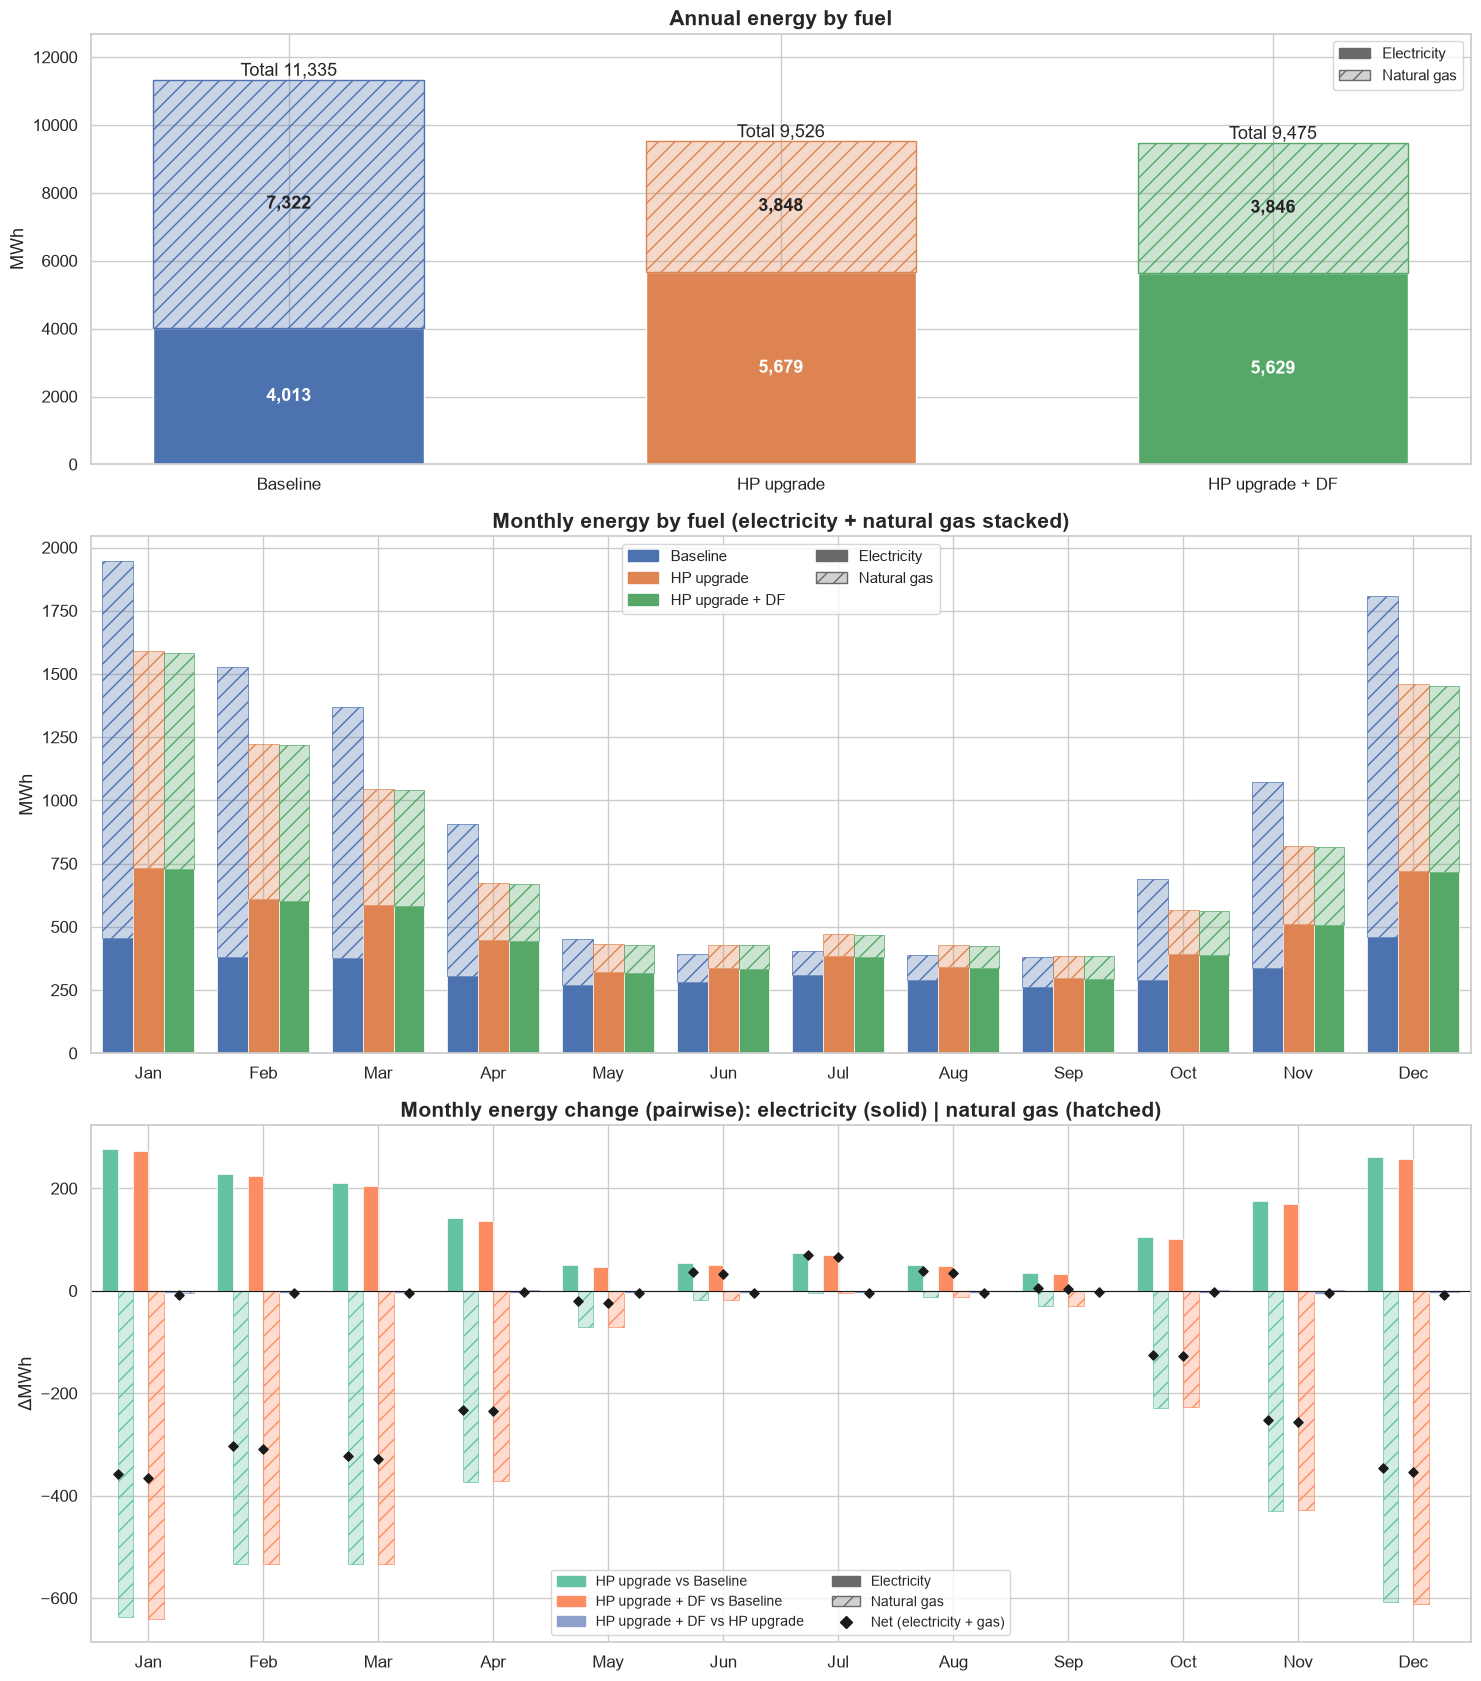

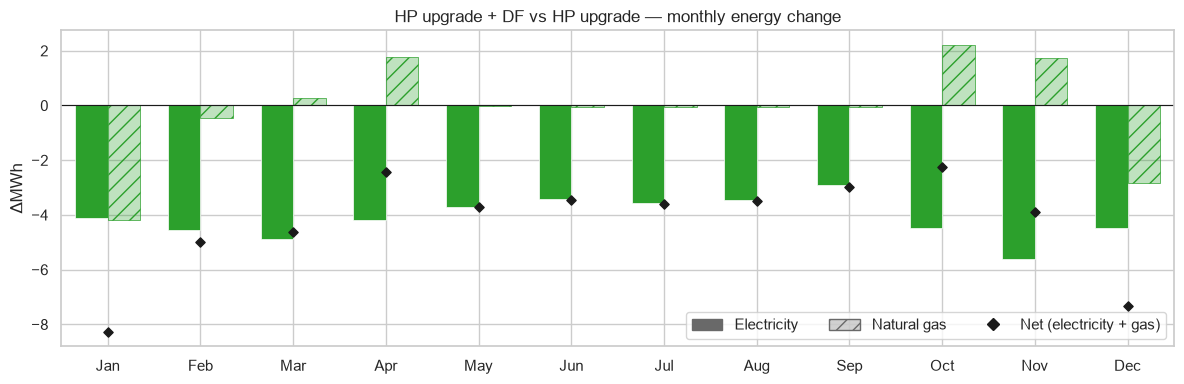

,Baseline,HP upgrade,HP upgrade + DF,Δ% HP upgrade vs Baseline,Δ% HP upgrade + DF vs Baseline,Δ% HP upgrade + DF vs HP upgrade
Jan,456.02,733.86,729.76,60.93,60.03,-0.56
Feb,379.32,608.14,603.60,60.32,59.13,-0.75
Mar,375.78,585.51,580.62,55.81,54.51,-0.83
Apr,306.00,447.63,443.44,46.28,44.91,-0.94
May,269.34,319.44,315.75,18.60,17.23,-1.16
Jun,282.31,336.87,333.47,19.33,18.12,-1.01
Jul,310.69,384.61,381.06,23.79,22.65,-0.92
Aug,290.30,341.38,337.94,17.60,16.41,-1.01
Sep,260.31,295.72,292.80,13.60,12.48,-0.99
Oct,287.88,392.75,388.28,36.43,34.88,-1.14


,Baseline,HP upgrade,HP upgrade + DF,Δ% HP upgrade vs Baseline,Δ% HP upgrade + DF vs Baseline,Δ% HP upgrade + DF vs HP upgrade
Jan,"1,491.31",855.37,851.19,-42.64,-42.92,-0.49
Feb,"1,148.49",616.04,615.57,-46.36,-46.40,-0.08
Mar,992.79,459.77,460.04,-53.69,-53.66,0.06
Apr,599.79,226.07,227.82,-62.31,-62.02,0.78
May,180.82,110.71,110.69,-38.77,-38.79,-0.03
Jun,110.54,92.90,92.85,-15.96,-16.00,-0.05
Jul,92.46,88.67,88.62,-4.10,-4.15,-0.05
Aug,99.26,86.77,86.71,-12.59,-12.65,-0.07
Sep,120.04,90.62,90.58,-24.51,-24.54,-0.05
Oct,401.38,172.21,174.43,-57.10,-56.54,1.29


In [19]:
monthly_mwh = sys_kw.groupby("month")[scen].sum() * dt_h / 1000
months = pd.to_datetime(monthly_mwh.index, format="%m").strftime("%b")
monthly_mwh.index = months
monthly_gas = gas_mwh.reindex(range(1, 13))[scen]
monthly_gas.index = months
monthly_delta = pd.DataFrame({cmp_label(a, b): monthly_mwh[a] - monthly_mwh[b] for a, b in COMPARISONS})
monthly_gas_delta = pd.DataFrame({cmp_label(a, b): monthly_gas[a] - monthly_gas[b] for a, b in COMPARISONS})
cols = [SCEN_COLORS[c] for c in scen]

# Annual energy by fuel
annual_fuel = pd.DataFrame({"Electricity (MWh)": monthly_mwh.sum(), "Natural gas (MWh)": monthly_gas.sum()})
annual_fuel["Total (MWh)"] = annual_fuel.sum(axis=1)
annual_fuel.to_csv(FIG_DIR / "annual_energy_by_fuel.csv")
fuel_pair = {}
for a, b in COMPARISONS:
    row = {}
    for k in annual_fuel.columns:
        row[f"Δ {k}"] = annual_fuel.loc[a, k] - annual_fuel.loc[b, k]
        row[f"Δ% {k.split(' (')[0]}"] = 100 * (annual_fuel.loc[a, k] / annual_fuel.loc[b, k] - 1)
    fuel_pair[cmp_label(a, b)] = row
fuel_pair = pd.DataFrame(fuel_pair).T
fuel_pair.to_csv(FIG_DIR / "annual_energy_by_fuel_pairwise.csv")
display(annual_fuel, fuel_pair)

# Highlight figure: annual (stacked), monthly (stacked), monthly pairwise change (electricity | gas side by side + net)
with plt.rc_context(HIGHLIGHT):
    fig, axes = plt.subplots(3, 1, figsize=(15, 17), gridspec_kw={"height_ratios": [1, 1.2, 1.2]})
    ax = axes[0]
    e, g = annual_fuel["Electricity (MWh)"], annual_fuel["Natural gas (MWh)"]
    ax.bar(scen, e, color=cols, edgecolor="white", width=0.55)
    ax.bar(scen, g, bottom=e, facecolor=[to_rgba(c, 0.3) for c in cols], edgecolor=cols, hatch="//", width=0.55)
    for i, c in enumerate(scen):
        ax.text(i, e[c] / 2, f"{e[c]:,.0f}", ha="center", va="center", color="white", fontweight="bold")
        ax.text(i, e[c] + g[c] / 2, f"{g[c]:,.0f}", ha="center", va="center", fontweight="bold")
        ax.text(i, e[c] + g[c], f"Total {e[c] + g[c]:,.0f}", ha="center", va="bottom")
    ax.set(title="Annual energy by fuel", ylabel="MWh", ylim=(0, 1.12 * (e + g).max()))
    ax.legend(handles=layer_legend([], [], "Electricity", "Natural gas"), loc="upper right")

    pair_bars(axes[1], monthly_mwh, monthly_gas, cols, stacked=True)
    axes[1].set(title="Monthly energy by fuel (electricity + natural gas stacked)", ylabel="MWh")
    axes[1].legend(handles=layer_legend(scen, cols, "Electricity", "Natural gas"), ncol=2)

    pair_bars(axes[2], monthly_delta, monthly_gas_delta, CMP_COLORS, net=True)
    axes[2].axhline(0, color="k", lw=0.8)
    axes[2].set(title="Monthly energy change (pairwise): electricity (solid) | natural gas (hatched)", ylabel="ΔMWh")
    axes[2].legend(handles=layer_legend(monthly_delta.columns, CMP_COLORS, "Electricity", "Natural gas",
                                        "Net (electricity + gas)"), ncol=2, fontsize=10)
    plt.tight_layout(); fig.savefig(FIG_DIR / "energy_annual_monthly.png", dpi=150); plt.show()

# Zoom: DF vs Up04 (small relative to the upgrade effect)
lab = cmp_label(DF, UP)
fig, ax = plt.subplots(figsize=(12, 4))
pair_bars(ax, monthly_delta[[lab]], monthly_gas_delta[[lab]], ["tab:green"], net=True, width=0.7)
ax.axhline(0, color="k", lw=0.8); ax.set(title=lab + " — monthly energy change", ylabel="ΔMWh")
ax.legend(handles=layer_legend([], [], "Electricity", "Natural gas", "Net (electricity + gas)"), ncol=3)
plt.tight_layout(); plt.savefig(FIG_DIR / "energy_monthly_df_vs_up04.png", dpi=150); plt.show()

monthly_tbl = pd.concat([monthly_mwh, monthly_mwh.sum().to_frame("Annual").T])
gas_tbl = pd.concat([monthly_gas, monthly_gas.sum().to_frame("Annual").T])
for a, b in COMPARISONS:
    monthly_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (monthly_tbl[a] / monthly_tbl[b] - 1)
    gas_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (gas_tbl[a] / gas_tbl[b] - 1)
monthly_tbl.to_csv(FIG_DIR / "monthly_energy_mwh.csv")
gas_tbl.to_csv(FIG_DIR / "monthly_gas_mwh.csv")
display(monthly_tbl)
gas_tbl


## Demand: annual, seasonal, monthly peaks

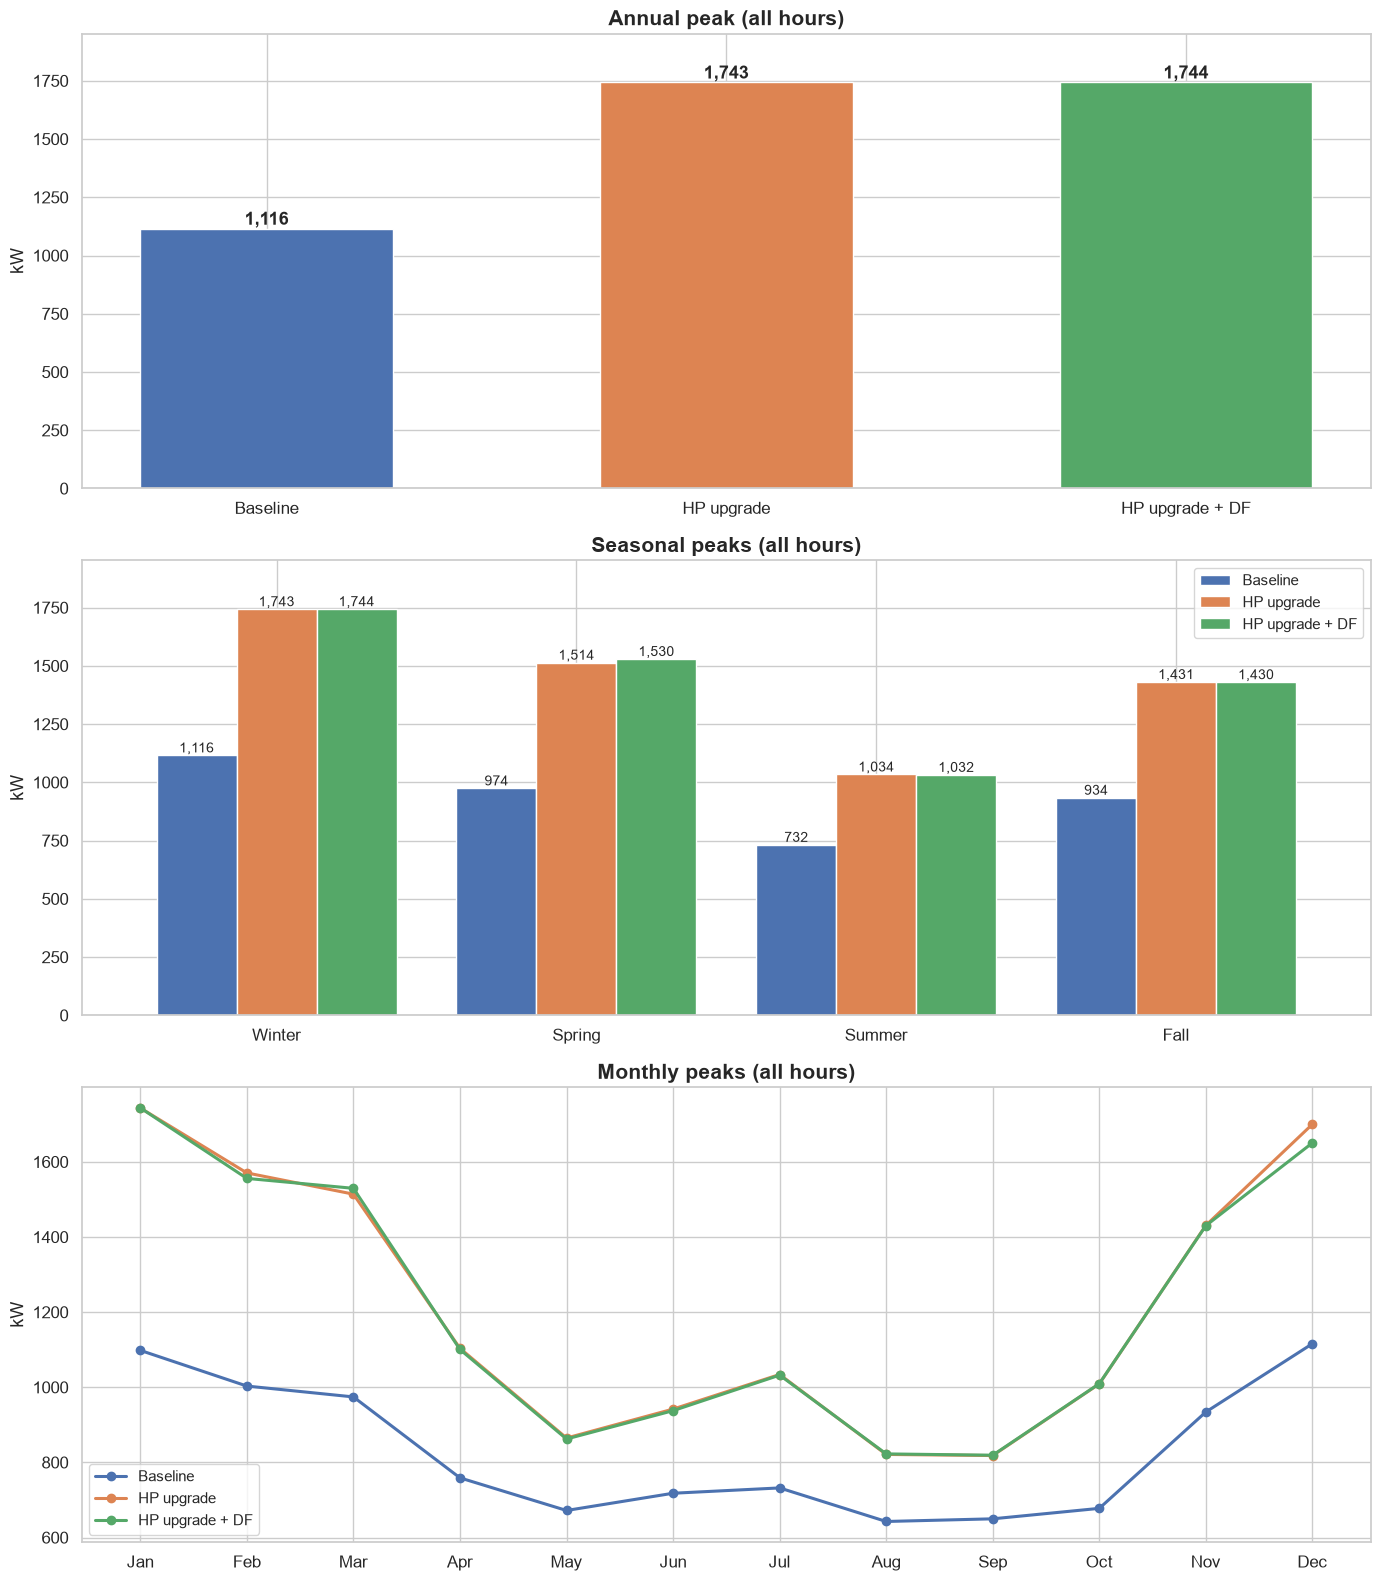

Peak (kW)                                                       \
        Baseline HP upgrade HP upgrade + DF Δ% HP upgrade vs Baseline   
season                                                                  
Winter  1,115.97   1,743.42        1,743.78                     56.22   
Spring    974.34   1,514.05        1,529.58                     55.39   
Summer    732.08   1,034.00        1,032.31                     41.24   
Fall      934.19   1,430.87        1,430.13                     53.17   

                                                                        \
       Δ% HP upgrade + DF vs Baseline Δ% HP upgrade + DF vs HP upgrade   
season                                                                   
Winter                          56.26                             0.02   
Spring                          56.99                             1.03   
Summer                          41.01                            -0.16   
Fall                            53.09                            -0.05   

                 Peak time                                          
                  Baseline          HP upgrade     HP upgrade + DF  
season                                                              
Winter 2024-12-21 18:45:00 2024-01-14 12:30:00 2024-01-14 12:30:00  
Spring 2024-03-10 22:15:00 2024-03-10 22:15:00 2024-03-10 22:15:00  
Summer 2024-07-15 17:15:00 2024-07-15 17:15:00 2024-07-15 17:15:00  
Fall   2024-11-30 13:15:00 2024-11-30 13:15:00 2024-11-30 13:15:00

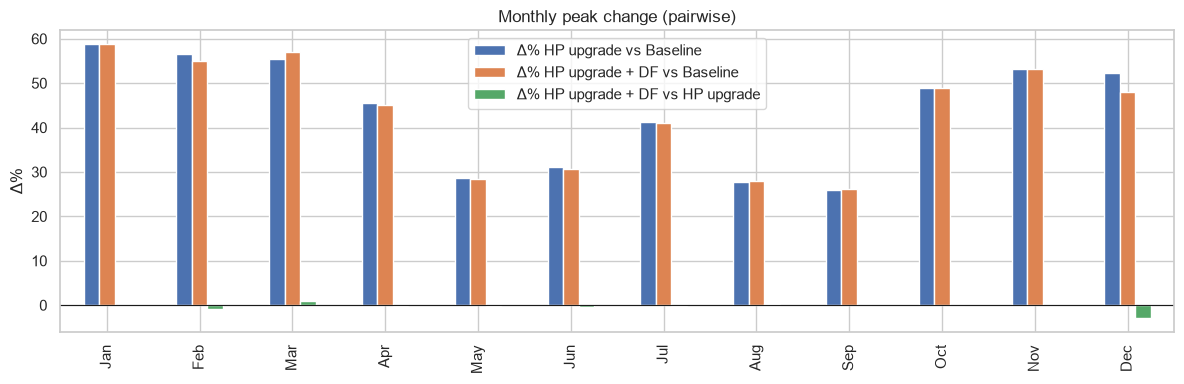

,Baseline,HP upgrade,HP upgrade + DF,Δ% HP upgrade vs Baseline,Δ% HP upgrade + DF vs Baseline,Δ% HP upgrade + DF vs HP upgrade
month,,,,,,
Jan,"1,098.22","1,743.42","1,743.78",58.75,58.78,0.02
Feb,"1,003.23","1,570.59","1,555.97",56.55,55.10,-0.93
Mar,974.34,"1,514.05","1,529.58",55.39,56.99,1.03
Apr,758.87,"1,103.71","1,100.58",45.44,45.03,-0.28
May,672.04,864.92,862.30,28.70,28.31,-0.30
Jun,717.93,941.91,937.71,31.20,30.61,-0.45
Jul,732.08,"1,034.00","1,032.31",41.24,41.01,-0.16
Aug,642.75,821.22,822.65,27.77,27.99,0.17
Sep,649.83,818.25,819.16,25.92,26.06,0.11


In [20]:
seasonal_pk = sys_kw.groupby("season")[scen].max().reindex(SEASON_ORDER)
seasonal_pk_time = sys_kw.groupby("season")[scen].idxmax().reindex(SEASON_ORDER)
monthly_pk = sys_kw.groupby("month")[scen].max()
monthly_pk.index = pd.to_datetime(monthly_pk.index, format="%m").strftime("%b")
cols = [SCEN_COLORS[c] for c in scen]

# Highlight figure: annual, seasonal and monthly all-hours peaks in three rows
with plt.rc_context(HIGHLIGHT):
    fig, axes = plt.subplots(3, 1, figsize=(14, 16))
    pk = summ["Peak demand (kW)"].astype(float)
    axes[0].bar(scen, pk, color=cols, width=0.55)
    for i, c in enumerate(scen):
        axes[0].text(i, pk[c], f"{pk[c]:,.0f}", ha="center", va="bottom", fontweight="bold")
    axes[0].set(title="Annual peak (all hours)", ylabel="kW", ylim=(0, 1.12 * pk.max()))
    seasonal_pk.plot.bar(ax=axes[1], color=cols, rot=0, width=0.8)
    for p in axes[1].patches:
        axes[1].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                         ha="center", va="bottom", fontsize=10)
    axes[1].set(title="Seasonal peaks (all hours)", ylabel="kW", xlabel="", ylim=(0, 1.12 * seasonal_pk.max().max()))
    for c, col in zip(scen, cols):
        axes[2].plot(range(12), monthly_pk[c], "-o", color=col, label=c)
    axes[2].set(title="Monthly peaks (all hours)", ylabel="kW")
    axes[2].set_xticks(range(12), monthly_pk.index); axes[2].legend()
    plt.tight_layout(); fig.savefig(FIG_DIR / "demand_peaks.png", dpi=150); plt.show()

sea_tbl = seasonal_pk.copy()
for a, b in COMPARISONS:
    sea_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (seasonal_pk[a] / seasonal_pk[b] - 1)
sea_tbl.to_csv(FIG_DIR / "seasonal_peaks_kw.csv")
display(pd.concat({"Peak (kW)": sea_tbl, "Peak time": seasonal_pk_time}, axis=1))

pk_tbl = monthly_pk.copy()
for a, b in COMPARISONS:
    pk_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (monthly_pk[a] / monthly_pk[b] - 1)

fig, ax = plt.subplots(figsize=(12, 4))
pk_tbl[[f"Δ% {cmp_label(a, b)}" for a, b in COMPARISONS]].plot.bar(ax=ax)
ax.axhline(0, color="k", lw=0.8); ax.set(title="Monthly peak change (pairwise)", ylabel="Δ%", xlabel="")
plt.tight_layout(); fig.savefig(FIG_DIR / "monthly_peak_pairwise.png", dpi=150); plt.show()

pk_tbl.to_csv(FIG_DIR / "monthly_peaks_kw.csv")
pk_tbl


## DF peak window: definition and justification
The DF scenario uses the ResStock 2025R1 measure `ResStockArgumentsPostHPXML`, run with `hvac_flex_peak_offset = 2°F`, `pre_peak_duration_hours = 0` (shed only) and `random_shift = 0`. It sets the thermostat back during a daily peak window. With no pre-peak period, the measure (`resources/common/schedule_modifier.rb::_get_peak_hour`) takes the window from `seasonal_shedding_peak_hours.json`. That file lists the Cambium 2050 MidCase net-load peak hours for each state and season (Gagnon et al., 2024). The window applies every day.

| Measure season | Months | NY window (standard time) |
|---|---|---|
| Winter | Dec, Jan, Feb, Mar | 17:00–21:00 |
| Intermediate | Apr, May, Oct, Nov | 17:00–21:00 |
| Summer | Jun–Sep | 18:00–22:00 |

**Evidence that this window was the one applied:**
- **Schedule:** in the DF `in.schedules.csv` (identical across the buildings checked), `peak_period` is 1 over these hours. During DST (Mar 11 to Nov 4) the file shifts the hours by +1 h, and EnergyPlus applies DST when it looks up schedule values. As a result, the window stays at the same clock hours in standard time, and the simulation output is in standard time.
- **Load response:** the DF − Up04 system delta is negative over exactly 16 intervals per day (4 h). It is followed by a rebound spike in the next interval. On the 15-min interval-end labels, the response appears one timestep later than nominal: labels 17:30–21:15 in winter and intermediate months, and 18:30–22:15 in summer. `WINDOW_LAG` (15 min) captures this lag in the mask. Set it to 0 to use the nominal window.

The **DF window** peak below is the maximum load within the window. The **All hours** peak (the earlier analysis) can occur outside the window. For example, the annual peak on Jan 14 at 12:30 falls outside the window, and DF is not designed to reduce such peaks.


bldg0000510 peak_period windows (schedule-file clock; +1 h during DST, Mar 11–Nov 4):


,window
2023-01-01,17:00–21:00
2023-03-11,18:00–22:00
2023-06-01,19:00–23:00
2023-10-01,18:00–22:00
2023-11-04,17:00–21:00


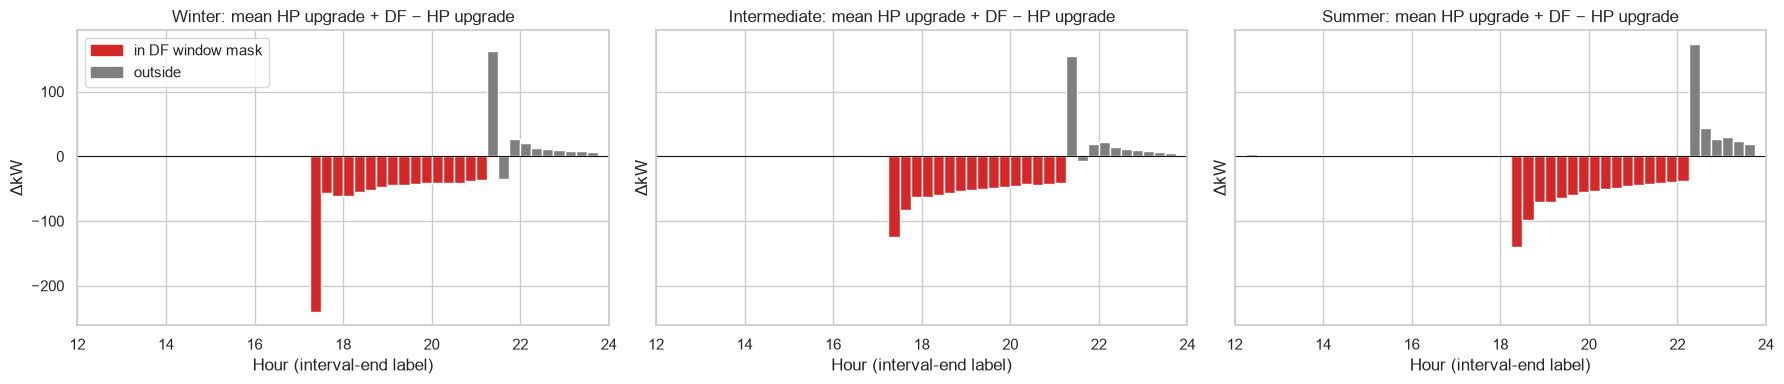

In [21]:
# Verify the window: (1) DF schedule peak_period flags, (2) mean DF − Up04 delta by time of day with the window mask shaded
from matplotlib.patches import Patch

sched = sorted((PATHS.models / "resstock_models_up04_df").glob("bldg*/run/in.schedules.csv"))
if sched:
    pp = pd.read_csv(sched[0], usecols=["peak_period"])["peak_period"]
    pp.index = pd.date_range("2023-01-01", periods=len(pp), freq="15min")  # interval start
    on = pp[pp > 0]
    w = on.groupby(on.index.normalize()).agg(lambda x: f"{x.index.min():%H:%M}–{x.index.max() + pd.Timedelta('15min'):%H:%M}")
    print(f"{sched[0].parts[-3]} peak_period windows (schedule-file clock; +1 h during DST, Mar 11–Nov 4):")
    display(w[w != w.shift()].rename("window").to_frame())

delta = sys_kw[DF] - sys_kw[UP]
tod = sys_kw.index.hour + sys_kw.index.minute / 60
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, s in zip(axes, ["winter", "intermediate", "summer"]):
    m = (sys_kw["df_season"] == s).to_numpy()
    prof = delta[m].groupby(tod[m]).mean()
    win = sys_kw.loc[m, "in_window"].groupby(tod[m]).mean().reindex(prof.index) > 0.5
    # bar spans the interval ending at its label
    ax.bar(prof.index, prof.values, width=-dt_h, align="edge", color=np.where(win, "tab:red", "tab:gray"))
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"{s.title()}: mean {DF} − {UP}", xlabel="Hour (interval-end label)", ylabel="ΔkW", xlim=(12, 24))
axes[0].legend(handles=[Patch(color="tab:red", label="in DF window mask"), Patch(color="tab:gray", label="outside")])
plt.tight_layout(); fig.savefig(FIG_DIR / "df_window_verification.png", dpi=150); plt.show()

## Peak demand: DF window vs all hours

All hours                                                       \
        Baseline HP upgrade HP upgrade + DF Δ% HP upgrade vs Baseline   
Annual  1,115.97   1,743.42        1,743.78                     56.22   
Winter  1,115.97   1,743.42        1,743.78                     56.22   
Spring    974.34   1,514.05        1,529.58                     55.39   
Summer    732.08   1,034.00        1,032.31                     41.24   
Fall      934.19   1,430.87        1,430.13                     53.17   
Jan     1,098.22   1,743.42        1,743.78                     58.75   
Feb     1,003.23   1,570.59        1,555.97                     56.55   
Mar       974.34   1,514.05        1,529.58                     55.39   
Apr       758.87   1,103.71        1,100.58                     45.44   
May       672.04     864.92          862.30                     28.70   
Jun       717.93     941.91          937.71                     31.20   
Jul       732.08   1,034.00        1,032.31                     41.24   
Aug       642.75     821.22          822.65                     27.77   
Sep       649.83     818.25          819.16                     25.92   
Oct       677.69   1,009.04        1,009.59                     48.89   
Nov       934.19   1,430.87        1,430.13                     53.17   
Dec     1,115.97   1,700.14        1,650.53                     52.35   

                                                                        \
       Δ% HP upgrade + DF vs Baseline Δ% HP upgrade + DF vs HP upgrade   
Annual                          56.26                             0.02   
Winter                          56.26                             0.02   
Spring                          56.99                             1.03   
Summer                          41.01                            -0.16   
Fall                            53.09                            -0.05   
Jan                             58.78                             0.02   
Feb                             55.10                            -0.93   
Mar                             56.99                             1.03   
Apr                             45.03                            -0.28   
May                             28.31                            -0.30   
Jun                             30.61                            -0.45   
Jul                             41.01                            -0.16   
Aug                             27.99                             0.17   
Sep                             26.06                             0.11   
Oct                             48.97                             0.05   
Nov                             53.09                            -0.05   
Dec                             47.90                            -2.92   

       DF window                                                       \
        Baseline HP upgrade HP upgrade + DF Δ% HP upgrade vs Baseline   
Annual  1,115.97   1,700.14        1,650.53                     52.35   
Winter  1,115.97   1,700.14        1,650.53                     52.35   
Spring    951.25   1,392.45        1,356.20                     46.38   
Summer    717.93     941.91          905.52                     31.20   
Fall      918.02   1,330.73        1,296.57                     44.96   
Jan     1,098.22   1,633.04        1,578.78                     48.70   
Feb     1,003.23   1,570.59        1,520.27                     56.55   
Mar       951.25   1,392.45        1,356.20                     46.38   
Apr       758.87   1,103.71        1,060.59                     45.44   
May       672.04     864.92          783.06                     28.70   
Jun       717.93     941.91          905.52                     31.20   
Jul       689.29     870.85          806.82                     26.34   
Aug       641.46     814.60          708.85                     26.99   
Sep       649.83     800.80          670.11                     23.23   
Oct       600.61     851.90          801.40 

Peak timestamps (interval-end):


All hours                                          \
                  Baseline          HP upgrade     HP upgrade + DF   
Annual 2024-12-21 18:45:00 2024-01-14 12:30:00 2024-01-14 12:30:00   
Winter 2024-12-21 18:45:00 2024-01-14 12:30:00 2024-01-14 12:30:00   
Spring 2024-03-10 22:15:00 2024-03-10 22:15:00 2024-03-10 22:15:00   
Summer 2024-07-15 17:15:00 2024-07-15 17:15:00 2024-07-15 17:15:00   
Fall   2024-11-30 13:15:00 2024-11-30 13:15:00 2024-11-30 13:15:00   

                 DF window                                          
                  Baseline          HP upgrade     HP upgrade + DF  
Annual 2024-12-21 18:45:00 2024-12-21 18:45:00 2024-12-21 18:45:00  
Winter 2024-12-21 18:45:00 2024-12-21 18:45:00 2024-12-21 18:45:00  
Spring 2024-03-20 19:45:00 2024-03-20 19:45:00 2024-03-20 19:45:00  
Summer 2024-06-18 18:45:00 2024-06-19 18:45:00 2024-06-19 19:00:00  
Fall   2024-11-30 20:00:00 2024-11-30 20:00:00 2024-11-30 20:00:00

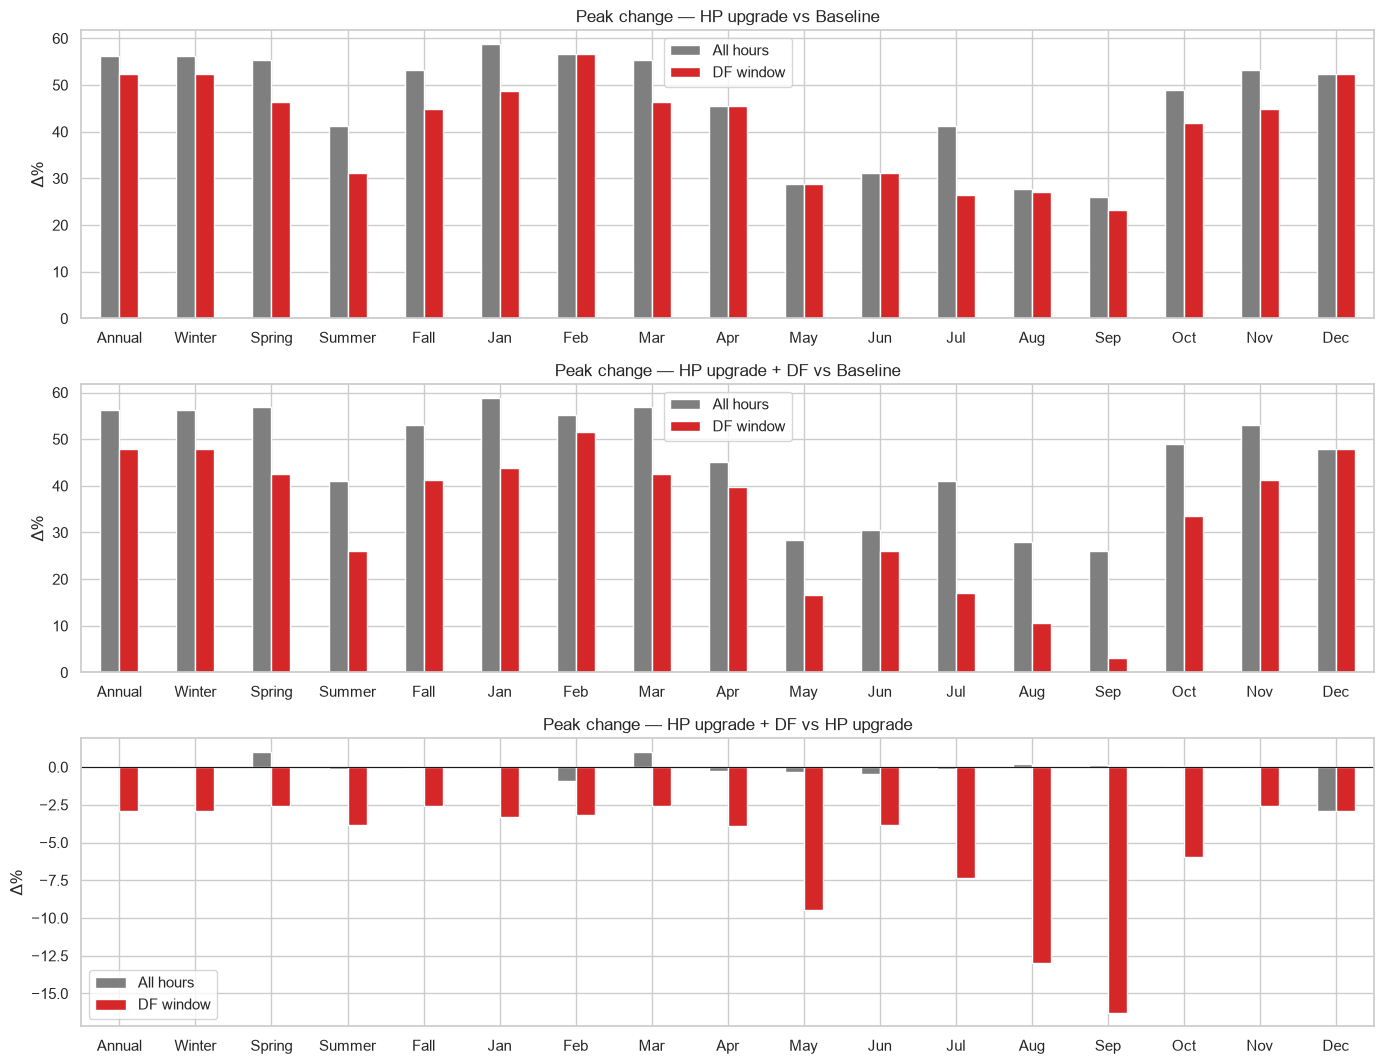

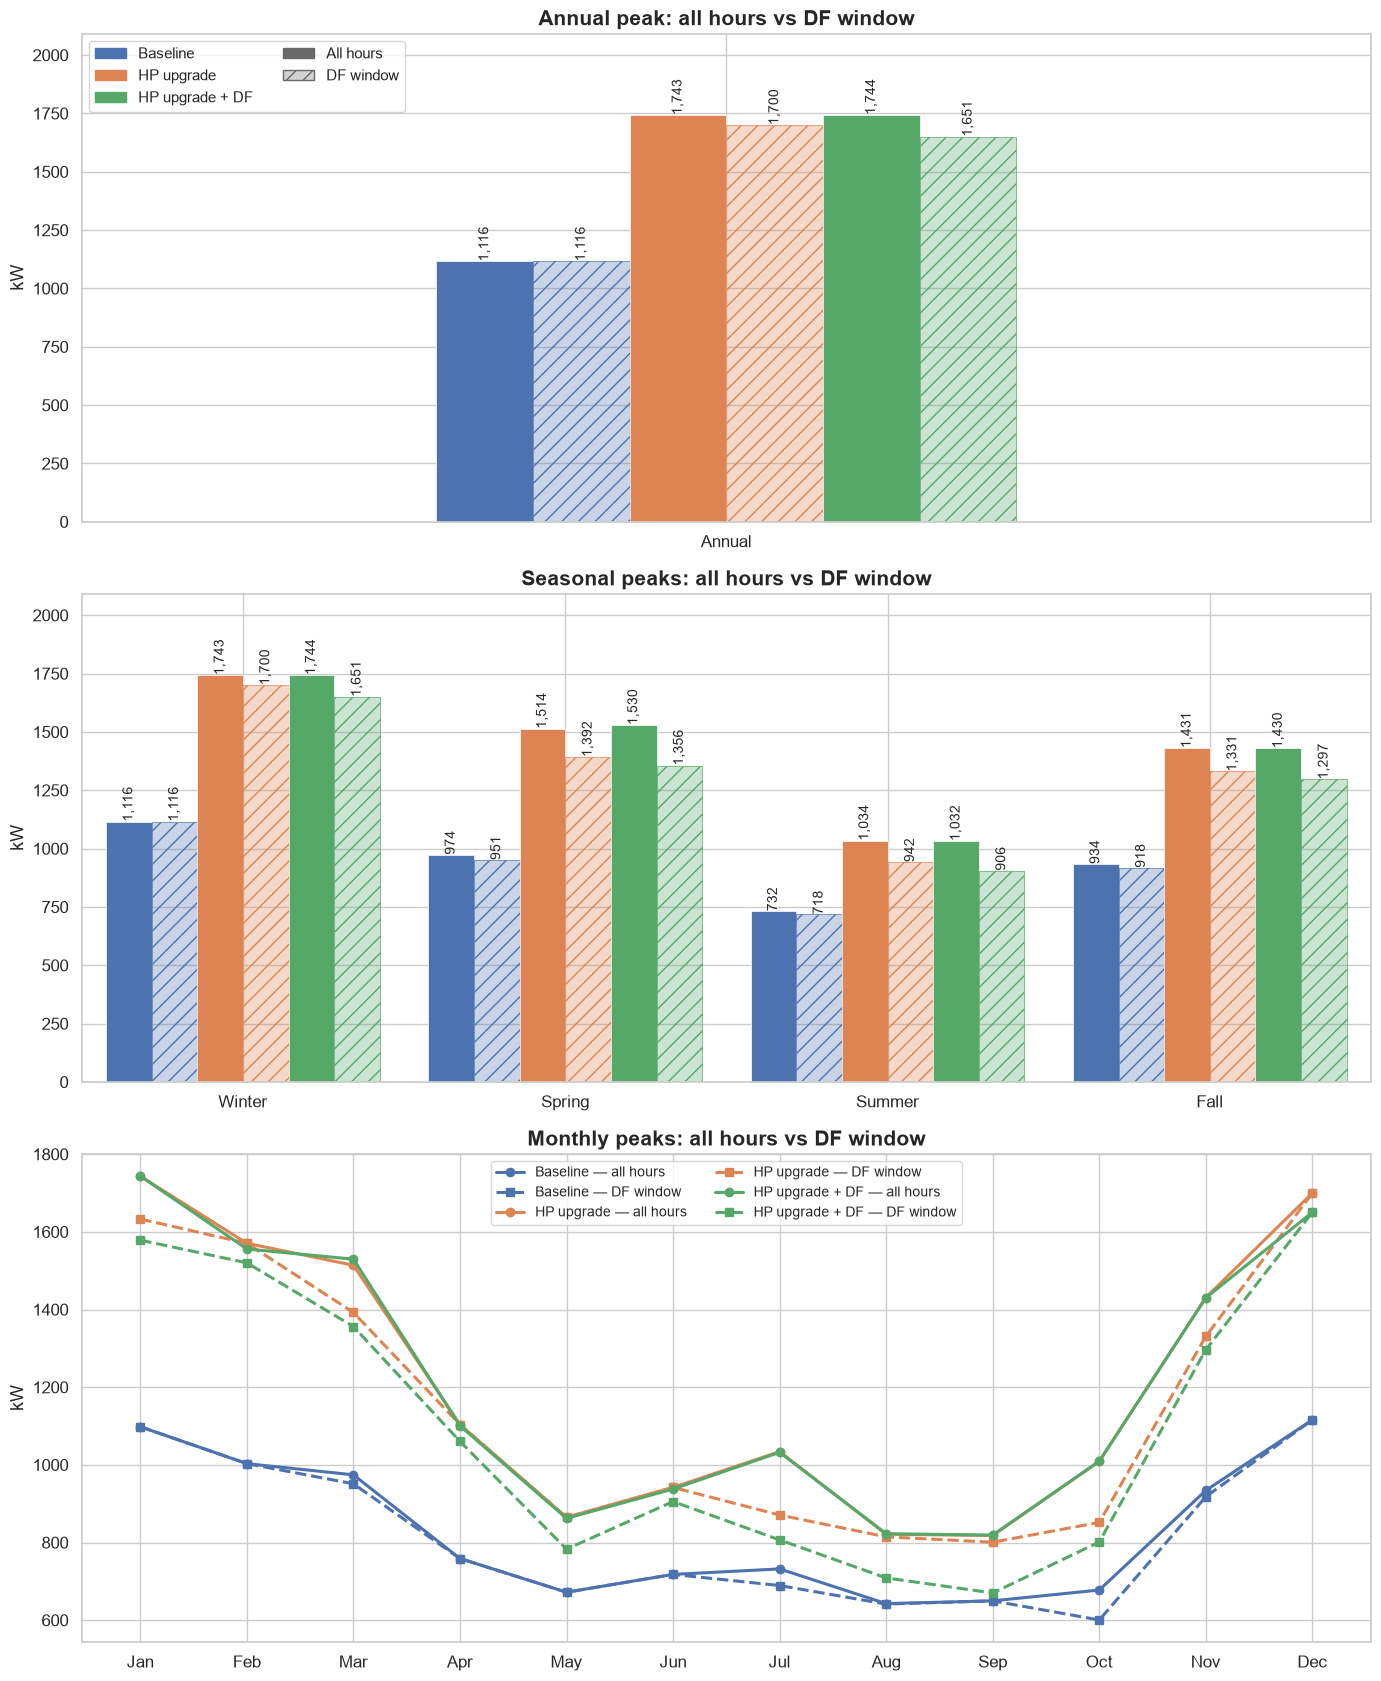

In [22]:
PERIODS = {"All hours": np.ones(len(sys_kw), bool), "DF window": sys_kw["in_window"].to_numpy()}


def peak_table(sub, fn="max"):
    ann = getattr(sub[scen], fn)().to_frame("Annual").T
    sea = getattr(sub.groupby("season")[scen], fn)().reindex(SEASON_ORDER)
    mon = getattr(sub.groupby("month")[scen], fn)()
    mon.index = pd.to_datetime(mon.index, format="%m").strftime("%b")
    return pd.concat([ann, sea, mon])


win_pk = pd.concat({p: peak_table(sys_kw[m]) for p, m in PERIODS.items()}, axis=1)
win_pk_time = pd.concat({p: peak_table(sys_kw[m], "idxmax") for p, m in PERIODS.items()}, axis=1)
for p in PERIODS:
    for a, b in COMPARISONS:
        win_pk[(p, f"Δ% {cmp_label(a, b)}")] = 100 * (win_pk[(p, a)] / win_pk[(p, b)] - 1)
win_pk = win_pk.sort_index(axis=1, level=0, sort_remaining=False)
win_pk.to_csv(FIG_DIR / "peaks_window_vs_all_kw.csv")
win_pk_time.to_csv(FIG_DIR / "peaks_window_vs_all_time.csv")
display(win_pk)
print("Peak timestamps (interval-end):")
display(win_pk_time.loc[["Annual"] + SEASON_ORDER])

# Pairwise peak Δ%: all hours vs DF window
fig, axes = plt.subplots(len(COMPARISONS), 1, figsize=(14, 3.6 * len(COMPARISONS)))
for ax, (a, b) in zip(axes, COMPARISONS):
    lab = f"Δ% {cmp_label(a, b)}"
    pd.DataFrame({p: win_pk[(p, lab)] for p in PERIODS}).plot.bar(ax=ax, color=["tab:gray", "tab:red"])
    ax.axhline(0, color="k", lw=0.8); ax.set(title=f"Peak change — {cmp_label(a, b)}", ylabel="Δ%", xlabel="")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); fig.savefig(FIG_DIR / "peak_change_window_vs_all.png", dpi=150); plt.show()

# Highlight figure (DF-window counterpart of the all-hours peak figure): annual, seasonal, monthly peaks;
# all hours = solid bars / lines, DF window = hatched bars / dashed lines
cols = [SCEN_COLORS[c] for c in scen]
mon = win_pk.index[1 + len(SEASON_ORDER):]
with plt.rc_context(HIGHLIGHT):
    fig, axes = plt.subplots(3, 1, figsize=(14, 17))
    for ax, rows, title, width in [(axes[0], ["Annual"], "Annual peak", 0.45),
                                   (axes[1], SEASON_ORDER, "Seasonal peaks", 0.85)]:
        allh, win = win_pk.loc[rows, "All hours"][scen], win_pk.loc[rows, "DF window"][scen]
        pair_bars(ax, allh, win, cols, width=width)
        w = width / len(scen)
        for i in range(len(rows)):
            for j, c in enumerate(scen):
                xj = i - width / 2 + (j + 0.5) * w
                for dx, v in [(-w / 4, allh.iloc[i][c]), (w / 4, win.iloc[i][c])]:
                    ax.text(xj + dx, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=10, rotation=90)
        ax.set(title=f"{title}: all hours vs DF window", ylabel="kW", ylim=(0, 1.2 * allh.max().max()))
    axes[0].legend(handles=layer_legend(scen, cols, "All hours", "DF window"), ncol=2, loc="upper left")
    for c, col in zip(scen, cols):
        axes[2].plot(mon, win_pk.loc[mon, ("All hours", c)], "-o", color=col, label=f"{c} — all hours")
        axes[2].plot(mon, win_pk.loc[mon, ("DF window", c)], "--s", color=col, label=f"{c} — DF window")
    axes[2].set(title="Monthly peaks: all hours vs DF window", ylabel="kW"); axes[2].legend(ncol=2, fontsize=10)
    plt.tight_layout(); fig.savefig(FIG_DIR / "demand_peaks_window_vs_all.png", dpi=150); plt.show()


In [23]:
# Shed & rebound by measure season: in-window energy, and peak in the 1 h right after the window
post = in_window(sys_kw.index - pd.Timedelta("1h")) & ~sys_kw["in_window"].to_numpy()
rows = []
for s in ["winter", "intermediate", "summer"]:
    ms = (sys_kw["df_season"] == s).to_numpy()
    w, q = sys_kw[ms & PERIODS["DF window"]], sys_kw[ms & post]
    n_days = ms.sum() * dt_h / 24
    for a, b in COMPARISONS:
        rows.append({
            "Measure season": s, "Comparison": cmp_label(a, b),
            "In-window energy Δ (MWh)": (w[a] - w[b]).sum() * dt_h / 1000,
            "In-window energy Δ%": 100 * (w[a].sum() / w[b].sum() - 1),
            "Avg in-window ΔkW": (w[a] - w[b]).mean(),
            "Post-window 1 h energy Δ (MWh)": (q[a] - q[b]).sum() * dt_h / 1000,
            "In-window peak Δ%": 100 * (w[a].max() / w[b].max() - 1),
            "Post-window 1 h peak Δ%": 100 * (q[a].max() / q[b].max() - 1),
            "Days": n_days,
        })
shed_tbl = pd.DataFrame(rows).set_index(["Measure season", "Comparison"])
shed_tbl.to_csv(FIG_DIR / "df_window_shed_rebound.csv")
shed_tbl

In-window energy Δ (MWh)  \
Measure season Comparison                                                
winter         HP upgrade vs Baseline                           154.26   
               HP upgrade + DF vs Baseline                      125.70   
               HP upgrade + DF vs HP upgrade                    -28.57   
intermediate   HP upgrade vs Baseline                            65.39   
               HP upgrade + DF vs Baseline                       37.35   
               HP upgrade + DF vs HP upgrade                    -28.04   
summer         HP upgrade vs Baseline                            39.72   
               HP upgrade + DF vs Baseline                       10.22   
               HP upgrade + DF vs HP upgrade                    -29.50   

                                              In-window energy Δ%  \
Measure season Comparison                                           
winter         HP upgrade vs Baseline                       45.62   
               HP upgrade + DF vs Baseline                  37.17   
               HP upgrade + DF vs HP upgrade                -5.80   
intermediate   HP upgrade vs Baseline                       25.89   
               HP upgrade + DF vs Baseline                  14.79   
               HP upgrade + DF vs HP upgrade                -8.82   
summer         HP upgrade vs Baseline                       16.63   
               HP upgrade + DF vs Baseline                   4.28   
               HP upgrade + DF vs HP upgrade               -10.59   

                                              Avg in-window ΔkW  \
Measure season Comparison                                         
winter         HP upgrade vs Baseline                    318.73   
               HP upgrade + DF vs Baseline               259.70   
               HP upgrade + DF vs HP upgrade             -59.03   
intermediate   HP upgrade vs Baseline                    134.00   
               HP upgrade + DF vs Baseline                76.54   
               HP upgrade + DF vs HP upgrade             -57.46   
summer         HP upgrade vs Baseline                     81.39   
               HP upgrade + DF vs Baseline                20.94   
               HP upgrade + DF vs HP upgrade             -60.45   

                                              Post-window 1 h energy Δ (MWh)  \
Measure season Comparison                                                      
winter         HP upgrade vs Baseline                                  40.09   
               HP upgrade + DF vs Baseline                             45.36   
               HP upgrade + DF vs HP upgrade                            5.27   
intermediate   HP upgrade vs Baseline                                  18.13   
               HP upgrade + DF vs Baseline                             23.87   
               HP upgrade + DF vs HP upgrade                            5.74   
summer         HP upgrade vs Baseline                                   6.18   
               HP upgrade + DF vs Baseline                             14.53   
               HP upgrade + DF vs HP upgrade                            8.35   

                                              In-window peak Δ%  \
Measure season Comparison                                         
winter         HP upgrade vs Baseline                     52.35   
               HP upgrade + DF vs Baseline                47.90   
               HP upgrade + DF vs HP upgrade              -2.92   
intermediate   HP upgrade vs Baseline                     44.96   
               HP upgrade + DF vs Baseline                41.24   
               HP upgrade + DF vs HP upgrade              -2.57   
summer         HP upgrade vs Baseline                     31.20   
               HP upgrade + DF vs Baseline                26.13   
               HP upgrade + DF vs HP upgrade              -3.86   

                                              Post-window 1 h peak Δ%   Days  
Measure season Comparison          

## Load duration curves & peak-day profiles

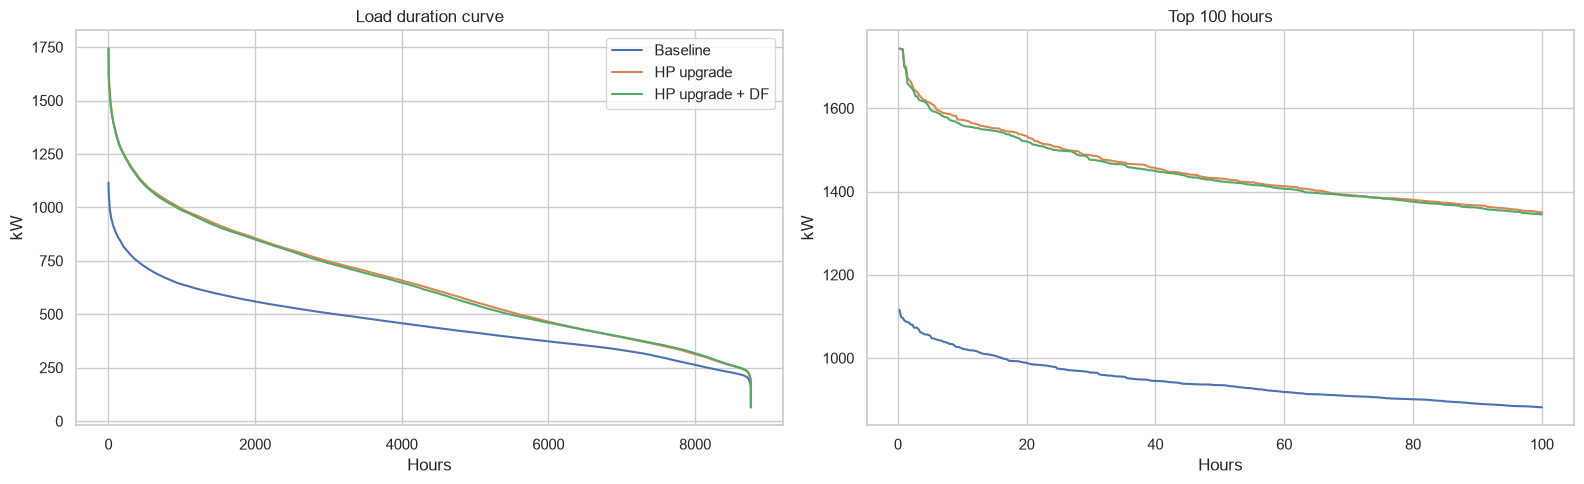

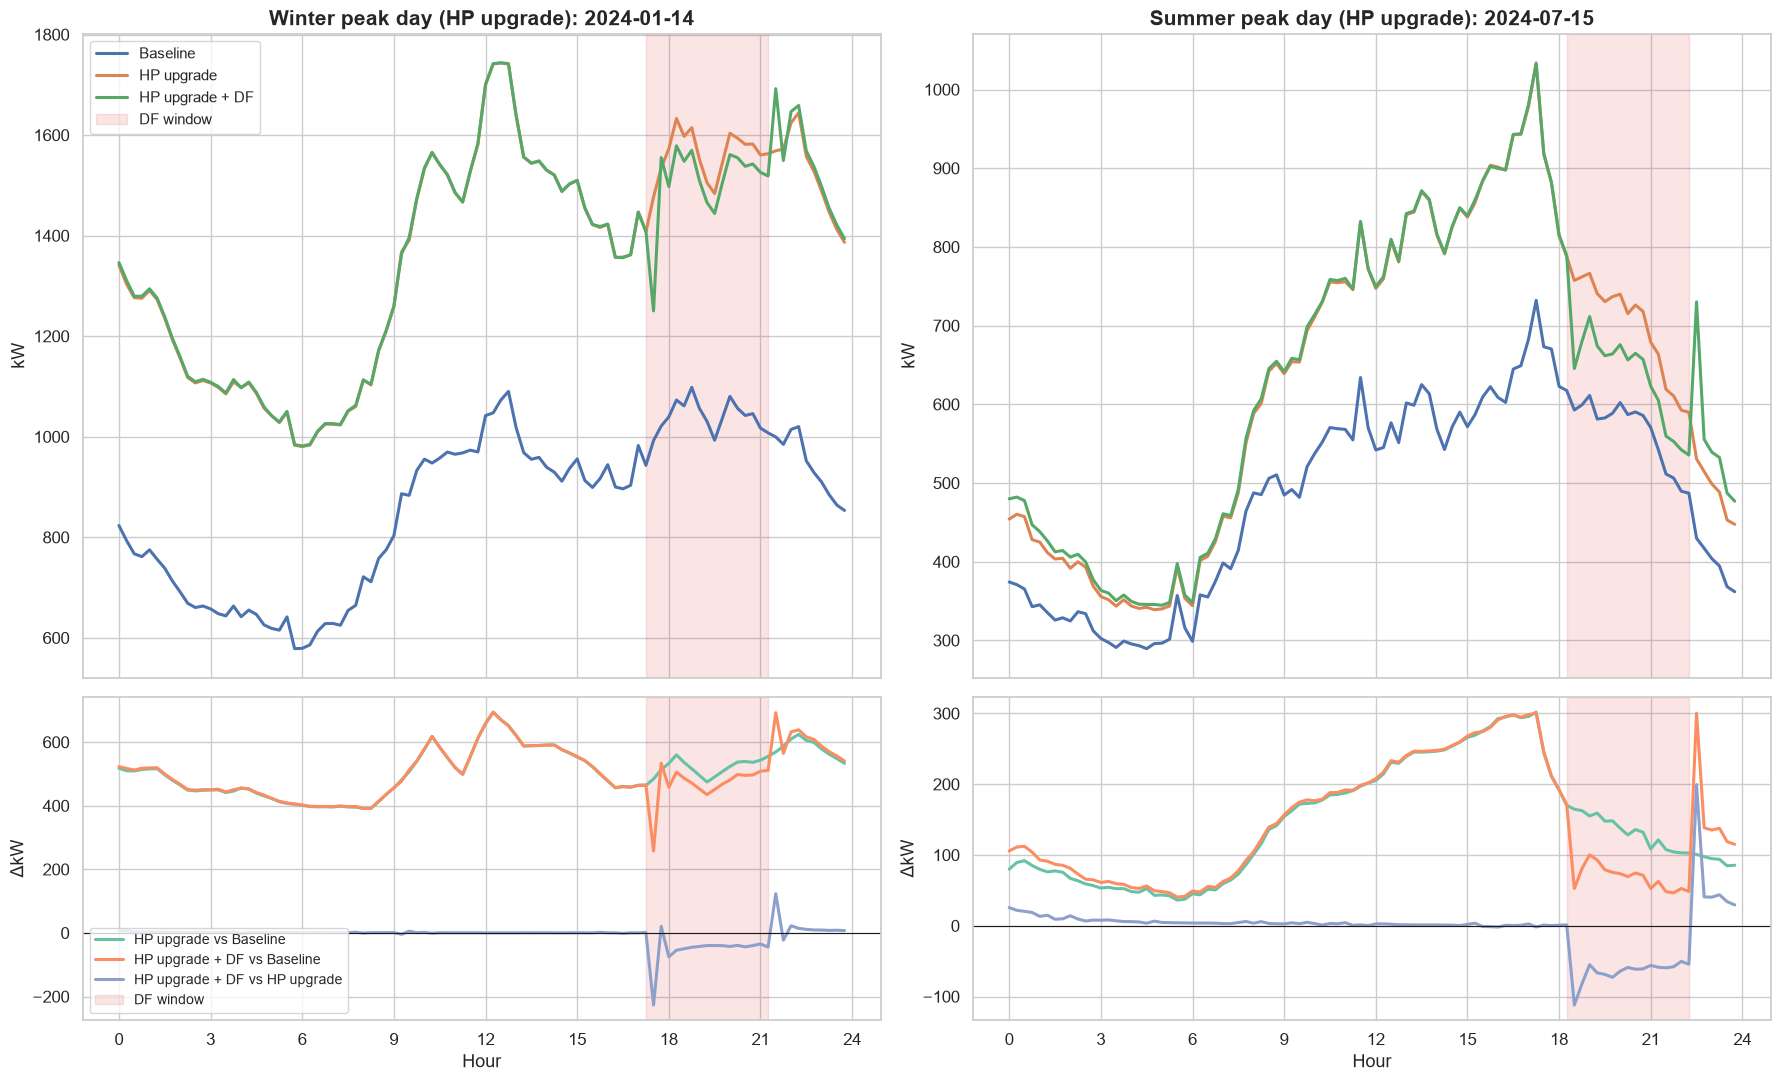

Daily peak (kW)  Peak hour  \
Season Date       Scenario                                      
Winter 2024-01-14 Baseline                1,098.22      18.75   
                  HP upgrade              1,743.42      12.50   
                  HP upgrade + DF         1,743.78      12.50   
Summer 2024-07-15 Baseline                  732.08      17.25   
                  HP upgrade              1,034.00      17.25   
                  HP upgrade + DF         1,032.31      17.25   

                                   DF-window peak (kW)  DF-window peak hour  \
Season Date       Scenario                                                    
Winter 2024-01-14 Baseline                    1,098.22                18.75   
                  HP upgrade                  1,633.04                18.25   
                  HP upgrade + DF             1,578.78                18.25   
Summer 2024-07-15 Baseline                      611.27                19.00   
                  HP upgrade                    766.46                19.00   
                  HP upgrade + DF               711.45                19.00   

                                   Daily energy (MWh)  DF-window energy (MWh)  
Season Date       Scenario                                                     
Winter 2024-01-14 Baseline                      20.70                    4.16  
                  HP upgrade                    32.91                    6.25  
                  HP upgrade + DF               32.77                    6.04  
Summer 2024-07-15 Baseline                      11.63                    2.26  
                  HP upgrade                    15.09                    2.79  
                  HP upgrade + DF               15.01                    2.53

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for c in scen:
    s = np.sort(sys_kw[c].values)[::-1]
    hrs = np.arange(1, len(s) + 1) * dt_h
    axes[0].plot(hrs, s, label=c)
    axes[1].plot(hrs[: int(100 / dt_h)], s[: int(100 / dt_h)], label=c)
axes[0].set(title="Load duration curve", xlabel="Hours", ylabel="kW")
axes[1].set(title="Top 100 hours", xlabel="Hours", ylabel="kW")
axes[0].legend(); plt.tight_layout(); fig.savefig(FIG_DIR / "load_duration.png", dpi=150); plt.show()

# Highlight figure: winter and summer peak days (from PEAK_DAY_SCEN's seasonal peaks); DF window shaded
peak_days = {sea: sys_kw.loc[sys_kw["season"] == sea, PEAK_DAY_SCEN].idxmax().normalize() for sea in ["Winter", "Summer"]}
day_rows = []
with plt.rc_context(HIGHLIGHT):
    fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    for j, (sea, d) in enumerate(peak_days.items()):
        day = sys_kw.loc[d: d + pd.Timedelta("1D") - pd.Timedelta("1s")]
        win = day["in_window"].to_numpy()
        day = day[scen]
        day.index = day.index.hour + day.index.minute / 60
        lo, hi = day.index[win].min() - dt_h, day.index[win].max()  # interval-end labels -> interval span
        for c in scen:
            axes[0, j].plot(day.index, day[c], color=SCEN_COLORS[c], label=c)
        axes[0, j].set(title=f"{sea} peak day ({PEAK_DAY_SCEN}): {d.date()}", ylabel="kW")
        for (a, b), col in zip(COMPARISONS, CMP_COLORS):
            axes[1, j].plot(day.index, day[a] - day[b], color=col, label=cmp_label(a, b))
        axes[1, j].axhline(0, color="k", lw=0.8)
        axes[1, j].set(xlabel="Hour", ylabel="ΔkW", xticks=range(0, 25, 3))
        for ax in axes[:, j]:
            ax.axvspan(lo, hi, color="tab:red", alpha=0.12, label="DF window")
        for c in scen:
            day_rows.append({"Season": sea, "Date": d.date(), "Scenario": c, "Daily peak (kW)": day[c].max(),
                             "Peak hour": day[c].idxmax(), "DF-window peak (kW)": day[c][win].max(),
                             "DF-window peak hour": day[c][win].idxmax(), "Daily energy (MWh)": day[c].sum() * dt_h / 1000,
                             "DF-window energy (MWh)": day[c][win].sum() * dt_h / 1000})
    axes[0, 0].legend(loc="upper left"); axes[1, 0].legend(loc="lower left", fontsize=10)
    plt.tight_layout(); fig.savefig(FIG_DIR / "peak_day_profiles_winter_summer.png", dpi=150); plt.show()

peak_day_tbl = pd.DataFrame(day_rows).set_index(["Season", "Date", "Scenario"])
peak_day_tbl.to_csv(FIG_DIR / "peak_day_summary.csv")
peak_day_tbl


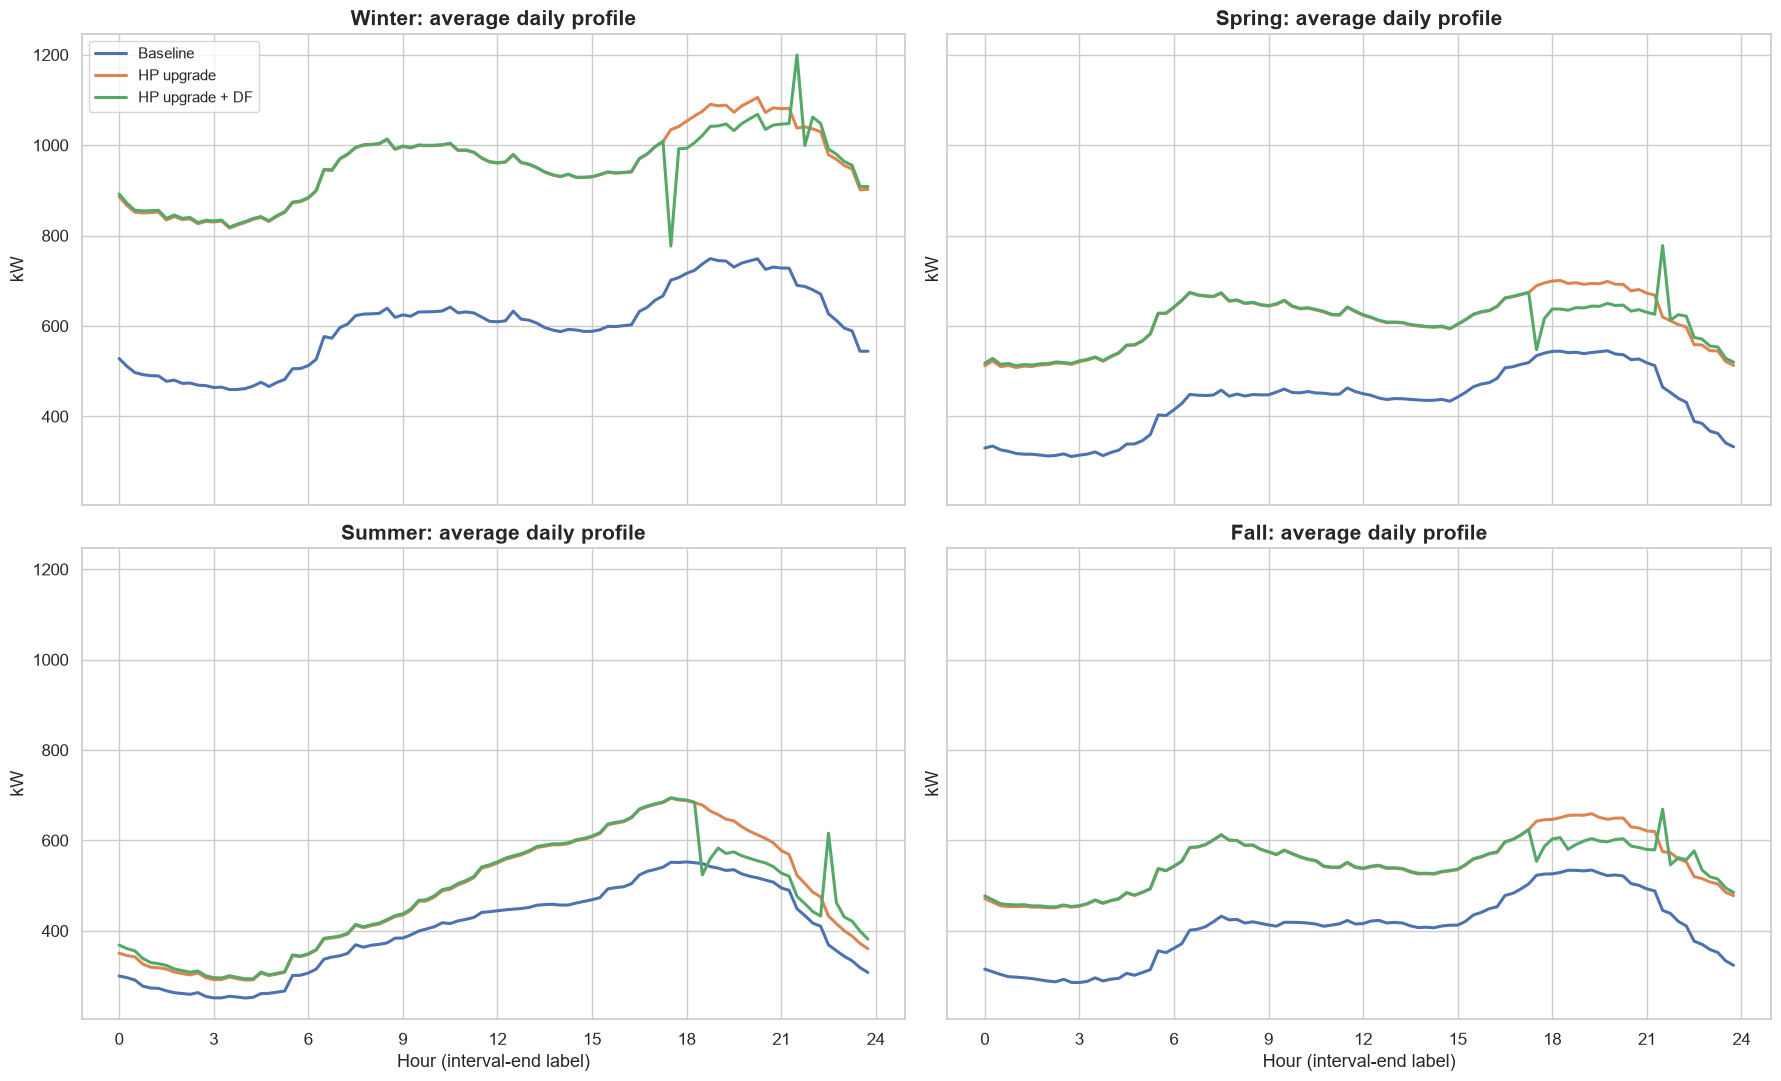

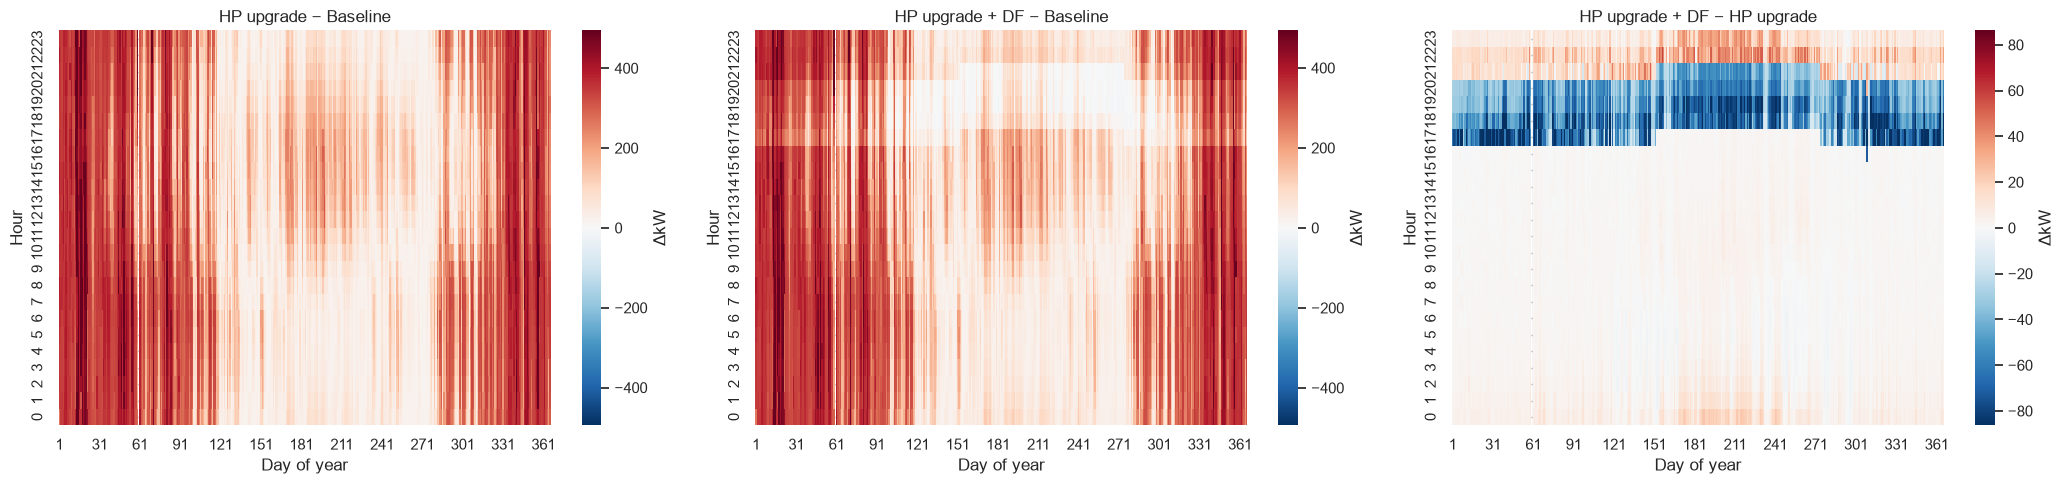

In [25]:
# Highlight figure: average daily profile by season (2 x 2)
hod = sys_kw.index.hour + sys_kw.index.minute / 60
with plt.rc_context(HIGHLIGHT):
    fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True, sharey=True)
    for ax, sea in zip(axes.flat, SEASON_ORDER):
        m = sys_kw["season"] == sea
        prof = sys_kw.loc[m, scen].groupby(hod[m]).mean()
        for c in scen:
            ax.plot(prof.index, prof[c], color=SCEN_COLORS[c], label=c)
        ax.set(title=f"{sea}: average daily profile", ylabel="kW", xticks=range(0, 25, 3))
    for ax in axes[1]:
        ax.set_xlabel("Hour (interval-end label)")
    axes[0, 0].legend(loc="upper left")
    plt.tight_layout(); fig.savefig(FIG_DIR / "seasonal_avg_profiles.png", dpi=150); plt.show()

# Heatmaps of pairwise change (day x hour)
fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(7 * len(COMPARISONS), 5))
for ax, (c, b) in zip(np.atleast_1d(axes), COMPARISONS):
    d = (sys_kw[c] - sys_kw[b]).resample("1h").mean()
    hm = d.groupby([d.index.hour, d.index.dayofyear]).mean().unstack()
    v = np.nanpercentile(np.abs(hm.values), 99)
    sns.heatmap(hm, ax=ax, cmap="RdBu_r", center=0, vmin=-v, vmax=v, cbar_kws={"label": "ΔkW"}, xticklabels=30)
    ax.set(title=f"{c} − {b}", xlabel="Day of year", ylabel="Hour"); ax.invert_yaxis()
plt.tight_layout(); fig.savefig(FIG_DIR / "delta_heatmaps.png", dpi=150); plt.show()


## Node-level (transformer) analysis

In [26]:
win_mask = sys_kw["in_window"].to_numpy()
node = {}
for c, df in data.items():
    node[(c, "energy_MWh")] = df.sum() * dt_h / 1000
    node[(c, "peak_kW")] = df.max()
    node[(c, "peak_window_kW")] = df[win_mask].max()
    for sea in SEASON_ORDER:
        node[(c, f"peak_{sea}_kW")] = df[df.index.month.map(SEASONS) == sea].max()
node = pd.DataFrame(node)
for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    node[(lab, "energy_Δ%")] = 100 * (node[(a, "energy_MWh")] / node[(b, "energy_MWh")] - 1)
    node[(lab, "peak_ΔkW")] = node[(a, "peak_kW")] - node[(b, "peak_kW")]
    node[(lab, "peak_Δ%")] = 100 * (node[(a, "peak_kW")] / node[(b, "peak_kW")] - 1)
    node[(lab, "peak_window_ΔkW")] = node[(a, "peak_window_kW")] - node[(b, "peak_window_kW")]
    node[(lab, "peak_window_Δ%")] = 100 * (node[(a, "peak_window_kW")] / node[(b, "peak_window_kW")] - 1)
node = node.replace([np.inf, -np.inf], np.nan)
node.to_csv(FIG_DIR / "node_summary.csv")

# Descriptive statistics across nodes
display(node.xs("peak_kW", axis=1, level=1).describe().T.join(
    node.xs("energy_MWh", axis=1, level=1).describe().T, lsuffix=" peak_kW", rsuffix=" energy_MWh"))

# Pairwise node changes: stats and count of nodes with peak up/down (all hours vs DF window)
pair_stats = {}
for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    for per, k in [("All hours", "peak"), ("DF window", "peak_window")]:
        dk = node[(lab, f"{k}_ΔkW")]
        pair_stats[(lab, per)] = {
            "mean peak ΔkW": dk.mean(),
            "median peak Δ%": node[(lab, f"{k}_Δ%")].median(),
            "median energy Δ%": node[(lab, "energy_Δ%")].median(),
            "# nodes peak ↑ (>0.1 kW)": (dk > 0.1).sum(),
            "# nodes peak ↓ (<-0.1 kW)": (dk < -0.1).sum(),
        }
pair_stats = pd.DataFrame(pair_stats).T
pair_stats.to_csv(FIG_DIR / "node_pairwise_stats.csv")
pair_stats

,count peak_kW,mean peak_kW,std peak_kW,min peak_kW,25% peak_kW,50% peak_kW,75% peak_kW,max peak_kW,count energy_MWh,mean energy_MWh,std energy_MWh,min energy_MWh,25% energy_MWh,50% energy_MWh,75% energy_MWh,max energy_MWh
Baseline,146.00,14.83,9.99,0.00,8.49,11.79,18.88,53.21,146.00,27.49,25.15,0.00,10.05,17.22,37.48,117.62
HP upgrade,146.00,18.31,12.72,0.00,10.02,13.56,23.07,69.36,146.00,38.89,34.77,0.00,16.24,24.81,50.31,164.04
HP upgrade + DF,146.00,18.30,12.71,0.00,9.87,13.52,23.13,69.36,146.00,38.56,34.46,0.00,16.02,24.61,49.73,162.26


mean peak ΔkW  median peak Δ%  \
HP upgrade vs Baseline        All hours           3.48           13.86   
                              DF window           3.10           13.03   
HP upgrade + DF vs Baseline   All hours           3.46           13.10   
                              DF window           2.79           10.84   
HP upgrade + DF vs HP upgrade All hours          -0.02            0.00   
                              DF window          -0.31           -0.53   

                                         median energy Δ%  \
HP upgrade vs Baseline        All hours             43.18   
                              DF window             43.18   
HP upgrade + DF vs Baseline   All hours             42.03   
                              DF window             42.03   
HP upgrade + DF vs HP upgrade All hours             -0.87   
                              DF window             -0.87   

                                         # nodes peak ↑ (>0.1 kW)  \
HP upgrade vs Baseline        All hours                    106.00   
                              DF window                    106.00   
HP upgrade + DF vs Baseline   All hours                    106.00   
                              DF window                    106.00   
HP upgrade + DF vs HP upgrade All hours                     15.00   
                              DF window                      5.00   

                                         # nodes peak ↓ (<-0.1 kW)  
HP upgrade vs Baseline        All hours                       2.00  
                              DF window                       1.00  
HP upgrade + DF vs Baseline   All hours                       2.00  
                              DF window                       5.00  
HP upgrade + DF vs HP upgrade All hours                      24.00  
                              DF window                      71.00

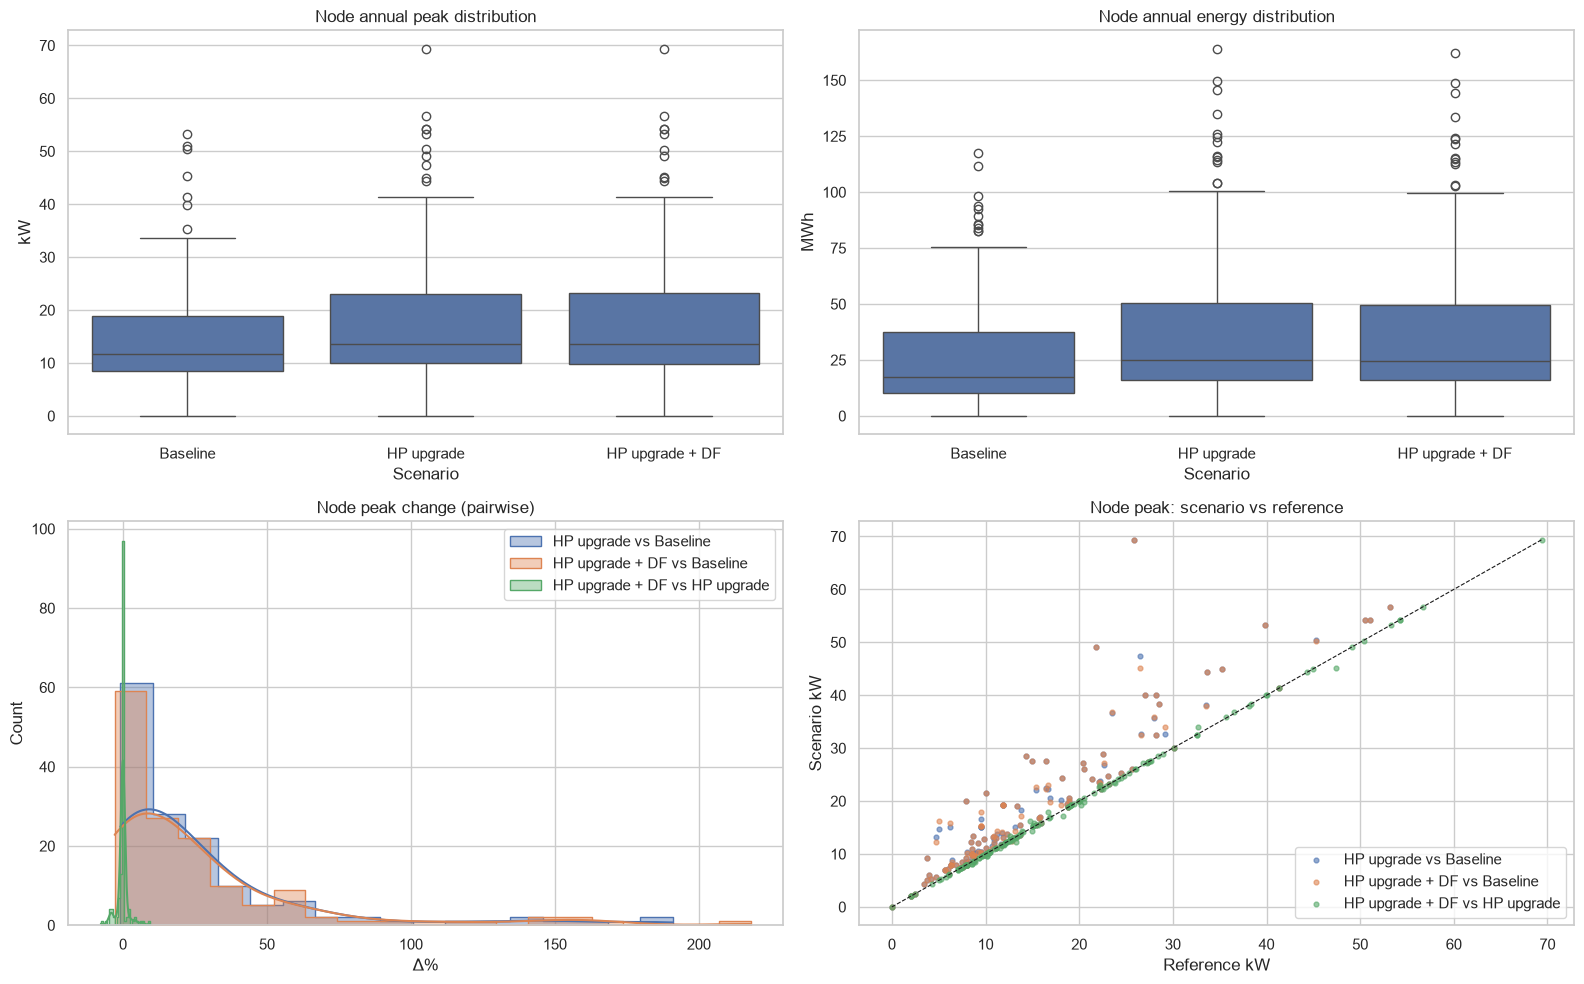

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
pk_long = node.xs("peak_kW", axis=1, level=1).melt(var_name="Scenario", value_name="kW")
en_long = node.xs("energy_MWh", axis=1, level=1).melt(var_name="Scenario", value_name="MWh")
sns.boxplot(data=pk_long, x="Scenario", y="kW", ax=axes[0, 0]); axes[0, 0].set_title("Node annual peak distribution")
sns.boxplot(data=en_long, x="Scenario", y="MWh", ax=axes[0, 1]); axes[0, 1].set_title("Node annual energy distribution")
for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    sns.histplot(node[(lab, "peak_Δ%")].dropna(), ax=axes[1, 0], label=lab, kde=True, element="step", alpha=0.4)
    axes[1, 1].scatter(node[(b, "peak_kW")], node[(a, "peak_kW")], s=12, alpha=0.6, label=lab)
axes[1, 0].set(title="Node peak change (pairwise)", xlabel="Δ%"); axes[1, 0].legend()
lim = node.xs("peak_kW", axis=1, level=1).max().max()
axes[1, 1].plot([0, lim], [0, lim], "k--", lw=0.8)
axes[1, 1].set(title="Node peak: scenario vs reference", xlabel="Reference kW", ylabel="Scenario kW"); axes[1, 1].legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "node_distributions.png", dpi=150); plt.show()

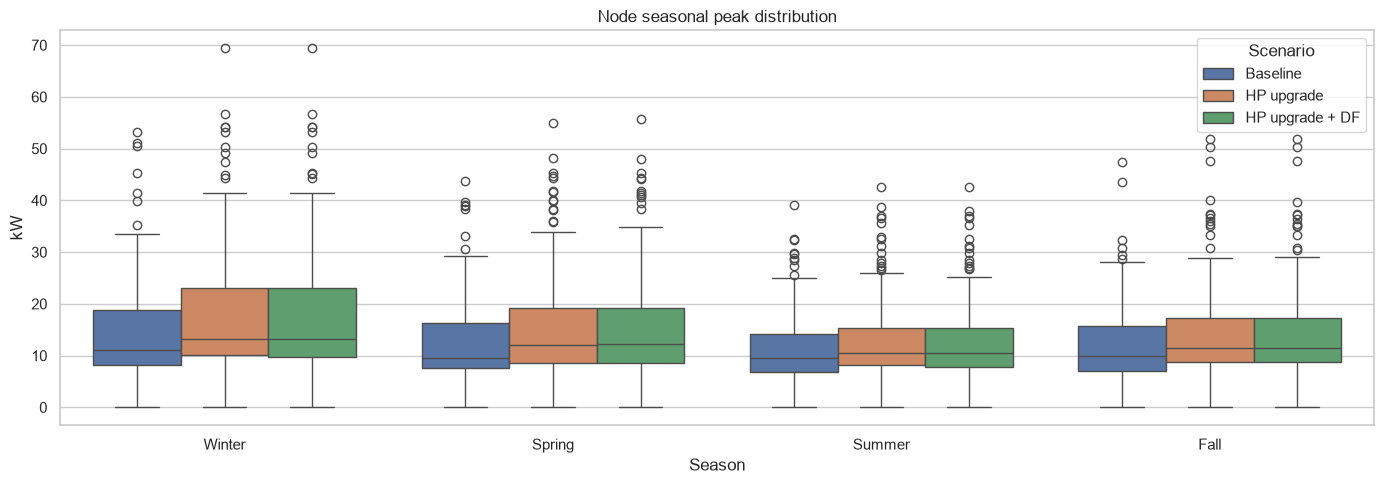

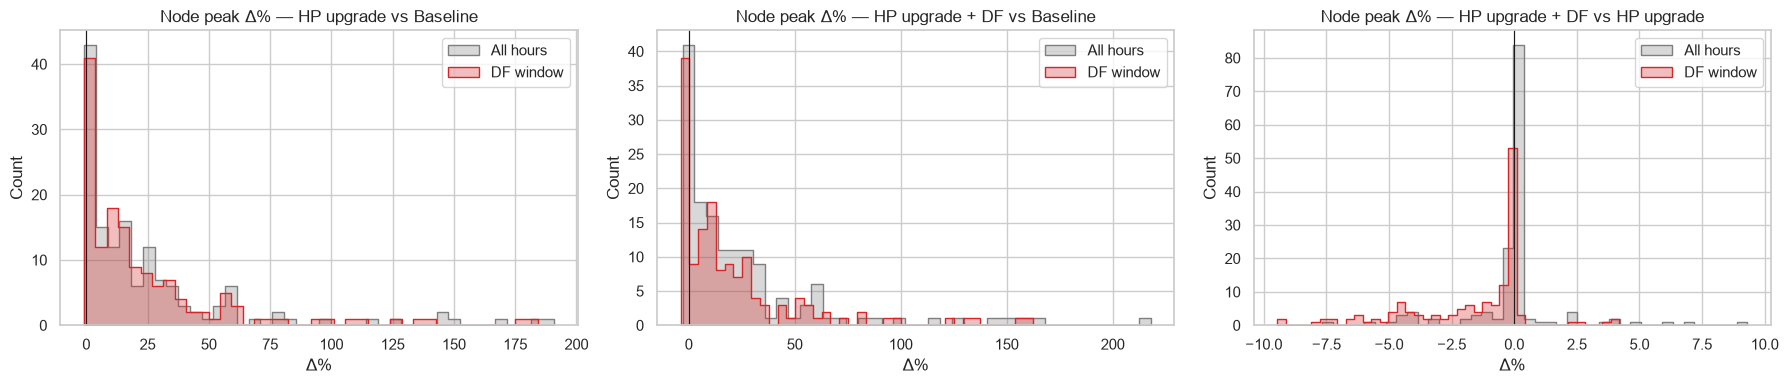

,All hours,DF window
Coincidence factor,,
Baseline,0.52,0.55
HP upgrade,0.65,0.68
HP upgrade + DF,0.65,0.68


Top 10 nodes by peak increase — HP upgrade vs Baseline


Baseline HP upgrade HP upgrade vs Baseline        
               peak_kW    peak_kW               peak_ΔkW peak_Δ%
220270653_RES    25.86      69.36                  43.50  168.22
220270497_RES    21.80      49.12                  27.32  125.31
220270566_RES    26.51      47.46                  20.95   79.03
220270519_RES    14.30      28.43                  14.13   98.84
220270568_RES    39.88      53.25                  13.37   33.53
220270617_RES    23.53      36.58                  13.04   55.44
220270660_RES    27.04      40.03                  12.98   48.01
220270506_RES    15.01      27.56                  12.56   83.69
220270550_RES     7.97      19.98                  12.01  150.78
310064740_RES    28.17      39.96                  11.79   41.86

Top 10 nodes by peak increase — HP upgrade + DF vs Baseline


Baseline HP upgrade + DF HP upgrade + DF vs Baseline        
               peak_kW         peak_kW                    peak_ΔkW peak_Δ%
220270653_RES    25.86           69.36                       43.50  168.22
220270497_RES    21.80           49.12                       27.32  125.31
220270566_RES    26.51           45.19                       18.68   70.47
220270519_RES    14.30           28.44                       14.14   98.92
220270568_RES    39.88           53.26                       13.38   33.54
220270617_RES    23.53           36.82                       13.29   56.46
220270660_RES    27.04           40.05                       13.01   48.09
220270506_RES    15.01           27.59                       12.58   83.86
220270550_RES     7.97           19.98                       12.01  150.78
310064740_RES    28.17           39.99                       11.82   41.94

Top 10 nodes by peak increase — HP upgrade + DF vs HP upgrade


HP upgrade HP upgrade + DF HP upgrade + DF vs HP upgrade        
                 peak_kW         peak_kW                      peak_ΔkW peak_Δ%
220269819_RES      14.79           16.16                          1.38    9.31
220270560_RES      32.66           34.00                          1.33    4.08
220269966_RES      16.66           17.85                          1.18    7.11
220534982_RES      22.25           23.13                          0.88    3.94
220270561_RES      12.63           13.41                          0.77    6.11
220270692_RES      15.19           15.95                          0.76    4.99
220270495_RES      22.06           22.58                          0.52    2.34
220270498_RES      13.86           14.37                          0.51    3.70
220270563_RES      15.02           15.36                          0.33    2.21
220270564_RES      15.02           15.36                          0.33    2.21

Top 10 nodes by DF-window peak reduction — HP upgrade + DF vs HP upgrade


HP upgrade HP upgrade + DF HP upgrade + DF vs HP upgrade  \
              peak_window_kW  peak_window_kW               peak_window_ΔkW   
220270497_RES          41.94           39.14                         -2.79   
220270653_RES          58.12           55.55                         -2.57   
220270566_RES          47.46           45.19                         -2.27   
310007575_RES          37.74           35.84                         -1.91   
220501626_RES          23.40           21.52                         -1.88   
220270506_RES          21.56           19.96                         -1.60   
220270519_RES          23.80           22.28                         -1.52   
220270550_RES          18.94           17.56                         -1.38   
220270695_RES          18.91           17.71                         -1.19   
220534968_RES          17.76           16.62                         -1.13   

                              
              peak_window_Δ%  
220270497_RES          -6.66  
220270653_RES          -4.42  
220270566_RES          -4.78  
310007575_RES          -5.05  
220501626_RES          -8.03  
220270506_RES          -7.44  
220270519_RES          -6.39  
220270550_RES          -7.26  
220270695_RES          -6.31  
220534968_RES          -6.38

In [28]:
# Seasonal node peak distributions & top nodes by peak increase
sea_long = pd.concat([
    node.xs(f"peak_{s}_kW", axis=1, level=1).melt(var_name="Scenario", value_name="kW").assign(Season=s)
    for s in SEASON_ORDER])
plt.figure(figsize=(14, 5))
sns.boxplot(data=sea_long, x="Season", y="kW", hue="Scenario")
plt.title("Node seasonal peak distribution"); plt.tight_layout()
plt.savefig(FIG_DIR / "node_seasonal_peaks.png", dpi=150); plt.show()

# Node peak change: all hours vs DF window
fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(6 * len(COMPARISONS), 4))
for ax, (a, b) in zip(axes, COMPARISONS):
    lab = cmp_label(a, b)
    for k, per, col in [("peak_Δ%", "All hours", "tab:gray"), ("peak_window_Δ%", "DF window", "tab:red")]:
        sns.histplot(node[(lab, k)].dropna(), ax=ax, label=per, color=col, element="step", alpha=0.3, bins=40)
    ax.axvline(0, color="k", lw=0.8); ax.set(title=f"Node peak Δ% — {lab}", xlabel="Δ%"); ax.legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "node_peak_change_window_vs_all.png", dpi=150); plt.show()

# Coincidence factor: system peak / sum of node peaks
cf = pd.DataFrame({
    "All hours": {c: sys_kw[c].max() / data[c].max().sum() for c in scen},
    "DF window": {c: sys_kw.loc[win_mask, c].max() / data[c][win_mask].max().sum() for c in scen},
})
display(cf.rename_axis("Coincidence factor"))

for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    top = node[[(b, "peak_kW"), (a, "peak_kW"), (lab, "peak_ΔkW"), (lab, "peak_Δ%")]].sort_values((lab, "peak_ΔkW"))
    print(f"Top 10 nodes by peak increase — {lab}"); display(top.tail(10)[::-1])
    if (a, b) == (DF, UP):
        top_w = node[[(b, "peak_window_kW"), (a, "peak_window_kW"), (lab, "peak_window_ΔkW"), (lab, "peak_window_Δ%")]]
        print(f"Top 10 nodes by DF-window peak reduction — {lab}"); display(top_w.sort_values((lab, "peak_window_ΔkW")).head(10))